**Linear LogReg probe PCA on English 5000 data ONLY ON MBERT, new surprise and fear w/o emojis and clean code and BRIGHTER+XED English + German test set + mDeBERTa, with BALANCED calibration AND (printed) PROBE WEIGHTS! ALSO ADDED EVALUATION TO PROJECTION METHODS (+ probe). Additional German calibration and a 6D classifier + probe training on hand labeled data. Estonian is smaller. CORRECT ONE!!**

In [1]:
import pandas as pd
import numpy as np
import torch
from transformers import AutoTokenizer, AutoModel
from tqdm import tqdm
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, balanced_accuracy_score, f1_score
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA_FILE = "combined_arabic_balanced_1200_new_bestest_no_@_1041_laughing.csv"
MAX_LENGTH = 128
BATCH_SIZE = 32
RANDOM_STATE = 42

In [3]:
# Pooling

def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output.last_hidden_state
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()

    summed = torch.sum(token_embeddings * input_mask_expanded, dim=1)
    counts = torch.clamp(input_mask_expanded.sum(dim=1), min=1e-9)
    return summed / counts

def cls_pooling(model_output):
    return model_output.last_hidden_state[:, 0, :]

In [4]:
# Encoding
def encode_texts(text_list, tokenizer, model, device, batch_size=32, max_length=128):
    mean_embs = []
    cls_embs = []

    with torch.no_grad():
        for i in tqdm(range(0, len(text_list), batch_size), desc="Encoding"):
            batch_texts = text_list[i:i + batch_size]

            encoded = tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=max_length,
                return_tensors="pt"
            )
            encoded = {k: v.to(device) for k, v in encoded.items()}

            outputs = model(**encoded)

            mean_emb = mean_pooling(outputs, encoded["attention_mask"])
            cls_emb = cls_pooling(outputs)

            mean_embs.append(mean_emb.cpu().numpy())
            cls_embs.append(cls_emb.cpu().numpy())

    return np.vstack(mean_embs), np.vstack(cls_embs)

In [5]:
# Centroids

def compute_centroids(embeddings, df, emotion_order):
    centroids = []
    for emotion in emotion_order:
        mask = (df["emotion"] == emotion).values
        centroids.append(embeddings[mask].mean(axis=0))
    centroids = np.vstack(centroids)
    return normalize(centroids, norm="l2")

In [6]:
# PCA

def plot_centroids_in_full_pca_2d(embeddings, centroids, emotion_order, title):
    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pca.fit(embeddings)
    centroids_2d = pca.transform(centroids)

    print(f"\n{title}")
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(emotion_order):
        plt.scatter(centroids_2d[i, 0], centroids_2d[i, 1], s=160)
        plt.text(
            centroids_2d[i, 0],
            centroids_2d[i, 1],
            emotion,
            fontsize=11,
            ha='center',
            va='center'
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

def plot_centroids_in_full_pca_3d(embeddings, centroids, emotion_order, title):
    pca = PCA(n_components=3, random_state=RANDOM_STATE)
    pca.fit(embeddings)
    centroids_3d = pca.transform(centroids)

    print(f"\n{title}")
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    for i, emotion in enumerate(emotion_order):
        ax.scatter(
            centroids_3d[i, 0],
            centroids_3d[i, 1],
            centroids_3d[i, 2],
            s=140
        )
        ax.text(
            centroids_3d[i, 0],
            centroids_3d[i, 1],
            centroids_3d[i, 2],
            emotion,
            fontsize=11
        )

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    plt.show()

In [7]:
# Probe training
def train_probe(embeddings, labels, name):
    X_train, X_test, y_train, y_test = train_test_split(
        embeddings,
        labels,
        test_size=0.2,
        random_state=RANDOM_STATE,
        stratify=labels
    )

    clf = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        random_state=RANDOM_STATE,
        class_weight="balanced"
    )
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)

    print(f"\n=== {name} probe ===")
    print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))
    print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, y_pred, average="weighted"), 4))
    print(classification_report(y_test, y_pred, digits=3))

    return clf

In [8]:
# Linear probe PCA
def get_probe_space(probe, embeddings, use_probabilities=False):
    if use_probabilities:
        return probe.predict_proba(embeddings)
    else:
        scores = probe.decision_function(embeddings)

        if scores.ndim == 1:
            scores = scores[:, None]

        return scores


def plot_probe_pca_2d(probe, embeddings, labels, emotion_order, title, use_probabilities=False):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_2d = pca.fit_transform(probe_space)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))
    for emotion in emotion_order:
        mask = (np.array(labels) == emotion)
        plt.scatter(
            X_2d[mask, 0],
            X_2d[mask, 1],
            label=emotion,
            alpha=0.35,
            s=10
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


def plot_probe_centroids_pca_2d(probe, embeddings, df, emotion_order, title, use_probabilities=False):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    # centroid in probe space
    centroids = []
    for emotion in emotion_order:
        mask = (df["emotion"] == emotion).values
        centroids.append(probe_space[mask].mean(axis=0))
    centroids = np.vstack(centroids)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    pca.fit(probe_space)
    centroids_2d = pca.transform(centroids)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    dx = (centroids_2d[:, 0].max() - centroids_2d[:, 0].min()) * 0.02
    dy = (centroids_2d[:, 1].max() - centroids_2d[:, 1].min()) * 0.02

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(emotion_order):
        plt.scatter(centroids_2d[i, 0], centroids_2d[i, 1], s=180)
        plt.text(
            centroids_2d[i, 0] + dx,
            centroids_2d[i, 1] + dy,
            emotion,
            fontsize=11
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()


def plot_probe_kde_pca_2d(probe, embeddings, labels, emotion_order, title, use_probabilities=True):
    probe_space = get_probe_space(probe, embeddings, use_probabilities=use_probabilities)

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    X_2d = pca.fit_transform(probe_space)

    print(f"\n{title}")
    print("Probe space shape:", probe_space.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))

    # scatter lightly underneath
    for emotion in emotion_order:
        mask = (np.array(labels) == emotion)
        plt.scatter(
            X_2d[mask, 0],
            X_2d[mask, 1],
            alpha=0.08,
            s=8,
            label=emotion
        )

    # KDE contours if seaborn is available
    try:
        import seaborn as sns

        for emotion in emotion_order:
            mask = (np.array(labels) == emotion)
            sns.kdeplot(
                x=X_2d[mask, 0],
                y=X_2d[mask, 1],
                levels=[0.25, 0.5],
                linewidths=2
            )
    except ImportError:
        print("seaborn not installed, showing scatter only.")

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()

In [9]:
# Example prediction
example_texts = [
    "I am so happy and excited about this!",
    "This is disgusting and makes me sick.",
    "I am terrified something bad will happen.",
    "I miss you so much and feel empty.",
    "What a wonderful surprise!",
    "I am furious and cannot stand this anymore."
]

def predict_examples(text_list, tokenizer, model, device, probe, use_mean=True):
    mean_embs, cls_embs = encode_texts(
        text_list, tokenizer, model, device,
        batch_size=8, max_length=MAX_LENGTH
    )

    embs = mean_embs if use_mean else cls_embs
    embs = normalize(embs, norm="l2")

    preds = probe.predict(embs)
    probs = probe.predict_proba(embs)

    for text, pred, prob in zip(text_list, preds, probs):
        top_idx = np.argsort(prob)[::-1][:3]
        top3 = [(probe.classes_[i], round(float(prob[i]), 3)) for i in top_idx]

        print("\nTEXT:", text)
        print("Predicted:", pred)
        print("Top-3:", top3)

In [10]:

# Probe weight analysis

def get_probe_weight_matrix(probe):
    """
    Returns normalized probe weight vectors.
    Shape: (n_classes, hidden_dim)
    """
    if not hasattr(probe, "coef_"):
        raise ValueError("Probe does not expose coef_. This works for LogisticRegression.")
    W = probe.coef_.copy()
    return normalize(W, norm="l2")


def plot_probe_weight_cosine_similarity(probe, class_order, title):
    W = get_probe_weight_matrix(probe)
    sim = cosine_similarity(W)
    sim_df = pd.DataFrame(sim, index=class_order, columns=class_order).round(3)

    print(f"\n{title}")
    print(sim_df)

    plt.figure(figsize=(7, 6))
    plt.imshow(sim, interpolation="nearest")
    plt.xticks(range(len(class_order)), class_order, rotation=45, ha="right")
    plt.yticks(range(len(class_order)), class_order)
    plt.colorbar()
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return sim_df


def plot_probe_weights_pca_2d(probe, class_order, title):
    """
    PCA on probe weight vectors themselves.
    Each point = one emotion direction.
    """
    W = get_probe_weight_matrix(probe)

    # with few classes, max possible rank is limited
    n_comp = min(2, W.shape[0], W.shape[1])
    pca = PCA(n_components=n_comp, random_state=RANDOM_STATE)
    W_2d = pca.fit_transform(W)

    print(f"\n{title}")
    print("Weight matrix shape:", W.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(8, 6))
    for i, emotion in enumerate(class_order):
        plt.scatter(W_2d[i, 0], W_2d[i, 1], s=180)
        plt.text(W_2d[i, 0], W_2d[i, 1], emotion, fontsize=11)

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

    return W_2d, pca


def plot_probe_weights_pca_3d(probe, class_order, title):
    W = get_probe_weight_matrix(probe)

    n_comp = min(3, W.shape[0], W.shape[1])
    if n_comp < 3:
        print(f"\n{title}")
        print("Not enough dimensions/classes for 3D PCA.")
        return None, None

    pca = PCA(n_components=3, random_state=RANDOM_STATE)
    W_3d = pca.fit_transform(W)

    print(f"\n{title}")
    print("Weight matrix shape:", W.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    # 🔽 ADD THIS BLOCK
    print("\n3D PCA coordinates (per emotion):")
    coords_df = pd.DataFrame(W_3d, columns=["PC1", "PC2", "PC3"])
    coords_df["emotion"] = class_order
    print(coords_df.round(4).to_string(index=False))

    # Also print in Desmos-friendly format
    print("\nDesmos-friendly format:")
    for i, emotion in enumerate(class_order):
        x, y, z = W_3d[i]
        print(f"{emotion}: ({x:.4f}, {y:.4f}, {z:.4f})")

    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection="3d")

    for i, emotion in enumerate(class_order):
        ax.scatter(W_3d[i, 0], W_3d[i, 1], W_3d[i, 2], s=160)
        ax.text(W_3d[i, 0], W_3d[i, 1], W_3d[i, 2], emotion, fontsize=10)

    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_zlabel("PC3")
    plt.show()

    return W_3d, pca


def plot_probe_weights_vs_centroids_pca_2d(probe, centroids, class_order, title):
    """
    Compare probe weight vectors and class centroids in the same PCA space.
    PCA is fit on the combined matrix [weights; centroids].
    """
    W = get_probe_weight_matrix(probe)
    C = normalize(centroids.copy(), norm="l2")

    combined = np.vstack([W, C])

    pca = PCA(n_components=2, random_state=RANDOM_STATE)
    combined_2d = pca.fit_transform(combined)

    W_2d = combined_2d[:len(class_order)]
    C_2d = combined_2d[len(class_order):]

    print(f"\n{title}")
    print("Combined shape:", combined.shape)
    print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))

    plt.figure(figsize=(9, 7))

    for i, emotion in enumerate(class_order):
        # weights
        plt.scatter(W_2d[i, 0], W_2d[i, 1], marker="^", s=180)
        plt.text(W_2d[i, 0], W_2d[i, 1], f"{emotion}_W", fontsize=10)

        # centroids
        plt.scatter(C_2d[i, 0], C_2d[i, 1], marker="o", s=180)
        plt.text(C_2d[i, 0], C_2d[i, 1], f"{emotion}_C", fontsize=10)

        # line connecting them
        plt.plot(
            [W_2d[i, 0], C_2d[i, 0]],
            [W_2d[i, 1], C_2d[i, 1]],
            linestyle="--",
            alpha=0.5
        )

    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(alpha=0.25)
    plt.show()

    return W_2d, C_2d, pca


def plot_probe_weight_projection_histograms(probe, embeddings, labels, emotion_order, title_prefix):
    """
    For each emotion direction, project all embeddings onto that weight vector.
    This shows whether the corresponding class tends to score higher along its own direction.
    """
    W = get_probe_weight_matrix(probe)
    X = normalize(embeddings.copy(), norm="l2")
    label_array = np.array(labels)

    for i, emotion in enumerate(emotion_order):
        scores = X @ W[i]

        plt.figure(figsize=(8, 5))
        for e in emotion_order:
            mask = label_array == e
            plt.hist(scores[mask], bins=40, alpha=0.35, label=e, density=True)

        plt.title(f"{title_prefix}: projection onto '{emotion}' weight")
        plt.xlabel("Cosine-like projection score")
        plt.ylabel("Density")
        plt.legend()
        plt.grid(alpha=0.2)
        plt.show()

In [11]:

# Projection-based classifiers

def get_probe_weight_matrix(probe):
    """
    Returns normalized probe weight vectors.
    Shape: (n_classes, hidden_dim)
    """
    W = probe.coef_.copy()
    return normalize(W, norm="l2")


def predict_with_weight_cosine(embeddings, probe, class_order):
    """
    Classify by cosine similarity between embeddings and probe weight vectors.
    """
    X = normalize(embeddings.copy(), norm="l2")
    W = get_probe_weight_matrix(probe)  # already normalized

    scores = X @ W.T   # cosine-like similarity since both normalized
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores


def predict_with_prototypes(embeddings, centroids, class_order):
    """
    Classify by nearest normalized class centroid (cosine similarity).
    """
    X = normalize(embeddings.copy(), norm="l2")
    C = normalize(centroids.copy(), norm="l2")

    scores = X @ C.T
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores


def softmax_np(x):
    x = x - np.max(x, axis=1, keepdims=True)
    exp_x = np.exp(x)
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)


def evaluate_simple_classifier(gold_labels, preds, scores, class_order, name="Classifier"):
    """
    Evaluation for cosine / prototype classifiers.
    Uses softmax(scores) as pseudo-probabilities for log loss + confidence stats.
    """
    probs = softmax_np(scores)

    print(f"\n=== {name} on XED test ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    confidence_df = pd.DataFrame({
        "gold": gold_labels,
        "pred": preds,
        "confidence": pred_conf
    })

    per_class_conf = (
        confidence_df.groupby("gold")["confidence"]
        .agg(["mean", "std", "count"])
        .round(4)
        .rename_axis("emotion")
        .reset_index()
    )

    print("\nPer-class confidence stats:")
    print(per_class_conf.to_string(index=False))

    return {
        "preds": preds,
        "scores": scores,
        "probs": probs,
        "confusion_matrix": cm_df,
        "confidence_stats": per_class_conf,
    }
    
def predict_with_linear_scores(embeddings, probe, class_order, normalize_inputs=False):
    """
    Classify using the probe's raw linear scoring function:
        score_c = x · w_c + b_c

    If normalize_inputs=True, embeddings are L2-normalized first.
    This is still interpretable, but closer to the original logistic probe
    than cosine similarity to normalized weights.
    """
    X = embeddings.copy()
    if normalize_inputs:
        X = normalize(X, norm="l2")

    W = probe.coef_          # shape: (n_classes, dim)
    b = probe.intercept_     # shape: (n_classes,)

    scores = X @ W.T + b
    pred_idx = np.argmax(scores, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, scores

In [12]:
import numpy as np
import pandas as pd

from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Helpers

def softmax_np(scores):
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)


def fit_bias_only(X_calib, y_calib, probe, class_order, l2=0.01):
    """
    Freeze probe weights W, learn only bias b on calibration data.
    """
    W = probe.coef_.copy()
    old_b = probe.intercept_.copy()

    label_to_idx = {label: i for i, label in enumerate(class_order)}
    y_idx = np.array([label_to_idx[y] for y in y_calib])

    def objective(b):
        scores = X_calib @ W.T + b
        probs = softmax_np(scores)

        nll = -np.mean(np.log(probs[np.arange(len(y_idx)), y_idx] + 1e-12))

        # regularize toward original bias, so calibration does not overfit too much
        penalty = l2 * np.sum((b - old_b) ** 2)

        return nll + penalty

    result = minimize(
        objective,
        x0=old_b,
        method="BFGS"
    )

    return result.x


def predict_with_fixed_weights_new_bias(X, probe, new_b, class_order):
    W = probe.coef_.copy()
    scores = X @ W.T + new_b
    probs = softmax_np(scores)

    pred_idx = np.argmax(probs, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    return preds, probs, scores


def evaluate_bias_calibrated(X_test, y_test, probe, new_b, class_order, name):
    preds, probs, scores = predict_with_fixed_weights_new_bias(
        X_test,
        probe,
        new_b,
        class_order
    )
    
    
    # Top-3 accuracy
    
    top_k = 3

    # get indices of top-3 predictions per sample
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]

    # map labels to indices
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in y_test])

    # check if gold label is in top-k
    top_k_correct = [
        gold_idx[i] in top_k_preds[i]
        for i in range(len(gold_idx))
    ]

    top_k_acc = np.mean(top_k_correct)

    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "scores": scores,
        "confusion_matrix": cm_df
    }

In [13]:
# mBERT loading

MODEL_NAME = "FacebookAI/xlm-roberta-base"

df = pd.read_csv(DATA_FILE)
df["text"] = df["text"].astype(str)
df["emotion"] = df["emotion"].astype(str)

texts = df["text"].tolist()
labels = df["emotion"].tolist()
emotion_order = sorted(df["emotion"].unique())

print("Rows:", len(df))
print("Emotions:", emotion_order)

device = torch.device("cuda" if torch.cuda.is_available() else "mps")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME)
model.to(device)
model.eval()

Rows: 6246
Emotions: ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']


XLMRobertaModel(
  (embeddings): XLMRobertaEmbeddings(
    (word_embeddings): Embedding(250002, 768, padding_idx=1)
    (position_embeddings): Embedding(514, 768, padding_idx=1)
    (token_type_embeddings): Embedding(1, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): XLMRobertaEncoder(
    (layer): ModuleList(
      (0-11): 12 x XLMRobertaLayer(
        (attention): XLMRobertaAttention(
          (self): XLMRobertaSdpaSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): XLMRobertaSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-05, element

In [14]:
# mBERT info

# embeddings
mean_embeddings, cls_embeddings = encode_texts(
    texts, tokenizer, model, device,
    batch_size=BATCH_SIZE, max_length=MAX_LENGTH
)

print("Mean embeddings shape:", mean_embeddings.shape)
print("CLS embeddings shape:", cls_embeddings.shape)

# normalization
mean_embeddings_norm = normalize(mean_embeddings, norm="l2")
cls_embeddings_norm = normalize(cls_embeddings, norm="l2")  

# centroids
mean_centroids = compute_centroids(mean_embeddings_norm, df, emotion_order)
cls_centroids = compute_centroids(cls_embeddings_norm, df, emotion_order)

# cos similarity
mean_centroid_cos = cosine_similarity(mean_centroids)
cls_centroid_cos = cosine_similarity(cls_centroids)

print("\nCosine similarity between mean-pooled centroids:")
print(pd.DataFrame(mean_centroid_cos, index=emotion_order, columns=emotion_order).round(3))

print("\nCosine similarity between CLS centroids:")
print(pd.DataFrame(cls_centroid_cos, index=emotion_order, columns=emotion_order).round(3))



Encoding: 100%|██████████| 196/196 [00:51<00:00,  3.83it/s]

Mean embeddings shape: (6246, 768)
CLS embeddings shape: (6246, 768)

Cosine similarity between mean-pooled centroids:
          anger  disgust  fear  joy  sadness  surprise
anger       1.0      1.0   1.0  1.0      1.0       1.0
disgust     1.0      1.0   1.0  1.0      1.0       1.0
fear        1.0      1.0   1.0  1.0      1.0       1.0
joy         1.0      1.0   1.0  1.0      1.0       1.0
sadness     1.0      1.0   1.0  1.0      1.0       1.0
surprise    1.0      1.0   1.0  1.0      1.0       1.0

Cosine similarity between CLS centroids:
          anger  disgust  fear  joy  sadness  surprise
anger       1.0      1.0   1.0  1.0      1.0       1.0
disgust     1.0      1.0   1.0  1.0      1.0       1.0
fear        1.0      1.0   1.0  1.0      1.0       1.0
joy         1.0      1.0   1.0  1.0      1.0       1.0
sadness     1.0      1.0   1.0  1.0      1.0       1.0
surprise    1.0      1.0   1.0  1.0      1.0       1.0



Emotion centroids projected into full mean-pooled PCA space
Explained variance ratio: [0.3658 0.0625]


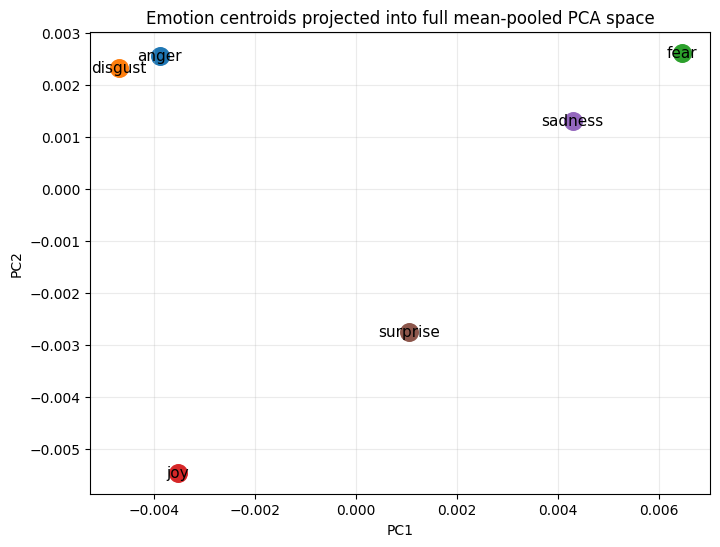


Emotion centroids in 3D PCA space (mean pooled, PCA fit on full data)
Explained variance ratio: [0.3658 0.0625 0.0319]


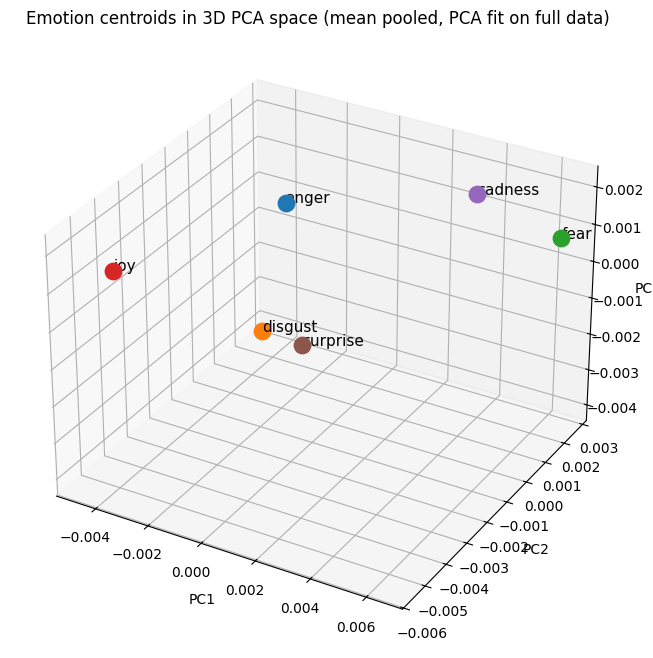


Emotion centroids projected into full CLS PCA space
Explained variance ratio: [0.7502 0.0281]


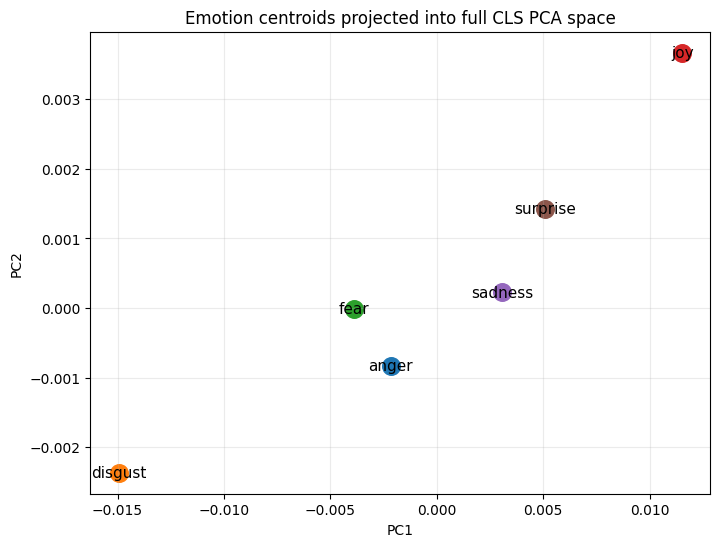

In [15]:
# mBERT visualizations

plot_centroids_in_full_pca_2d(
    mean_embeddings_norm,
    mean_centroids,
    emotion_order,
    "Emotion centroids projected into full mean-pooled PCA space"
)

plot_centroids_in_full_pca_3d(
    mean_embeddings_norm,
    mean_centroids,
    emotion_order,
    "Emotion centroids in 3D PCA space (mean pooled, PCA fit on full data)"
)

# Optional direct comparison with CLS
plot_centroids_in_full_pca_2d(
    cls_embeddings_norm,
    cls_centroids,
    emotion_order,
    "Emotion centroids projected into full CLS PCA space"
)


=== Mean-pooled probe ===
Accuracy: 0.288
Balanced accuracy: 0.288
Macro F1: 0.2628
Weighted F1: 0.2629
              precision    recall  f1-score   support

       anger      0.294     0.168     0.214       208
     disgust      0.298     0.514     0.377       208
        fear      0.209     0.312     0.250       208
         joy      0.386     0.526     0.445       209
     sadness      0.247     0.110     0.152       209
    surprise      0.241     0.096     0.137       208

    accuracy                          0.288      1250
   macro avg      0.279     0.288     0.263      1250
weighted avg      0.279     0.288     0.263      1250


=== CLS probe ===
Accuracy: 0.2488
Balanced accuracy: 0.2488
Macro F1: 0.1732
Weighted F1: 0.1733
              precision    recall  f1-score   support

       anger      0.271     0.077     0.120       208
     disgust      0.230     0.817     0.359       208
        fear      0.290     0.043     0.075       208
         joy      0.278     0.478   

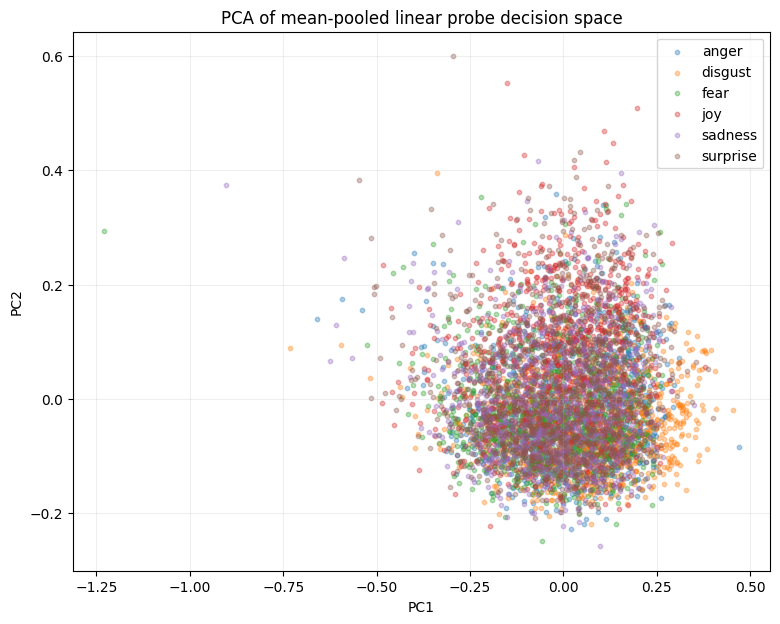


PCA of mean-pooled linear probe probability space
Probe space shape: (6246, 6)
Explained variance ratio: [0.6173 0.3236]


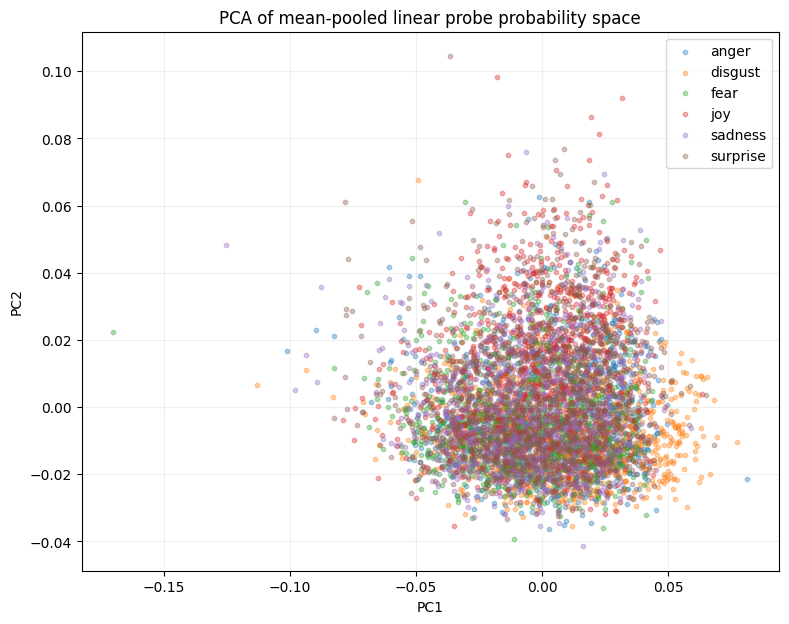


Emotion centroids in mean-pooled linear probe decision space
Probe space shape: (6246, 6)
Explained variance ratio: [0.6277 0.3155]


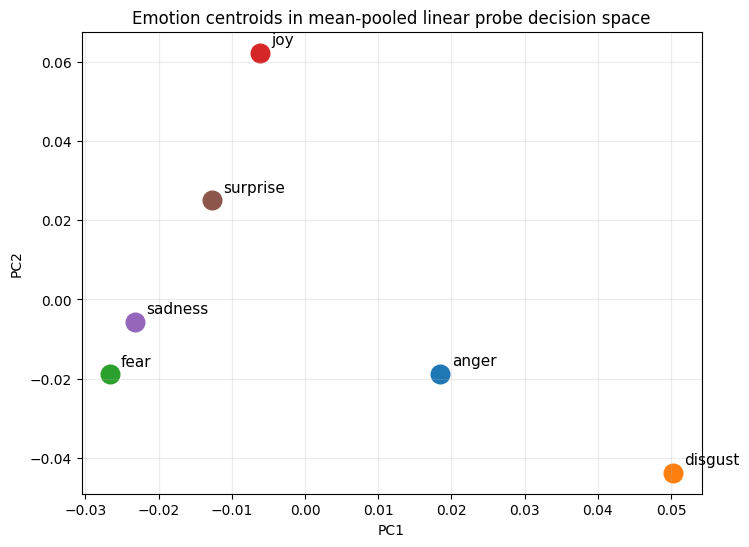


Emotion centroids in mean-pooled linear probe probability space
Probe space shape: (6246, 6)
Explained variance ratio: [0.6173 0.3236]


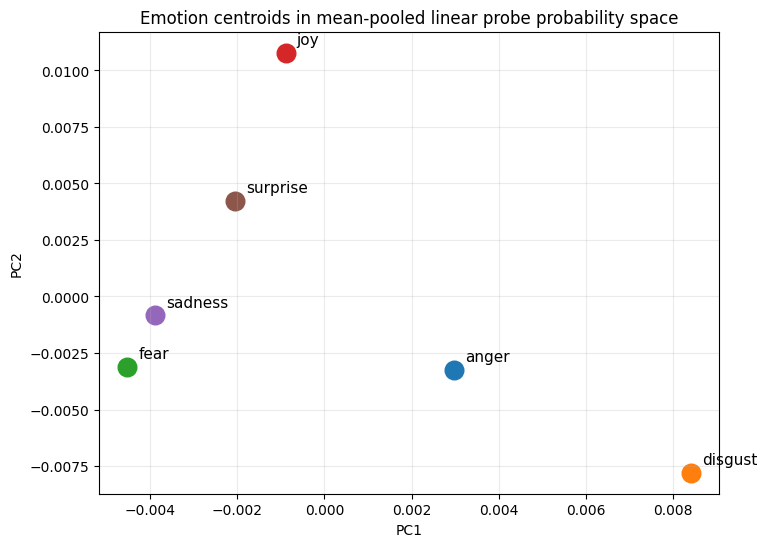


KDE contours of mean-pooled linear probe probability space
Probe space shape: (6246, 6)
Explained variance ratio: [0.6173 0.3236]


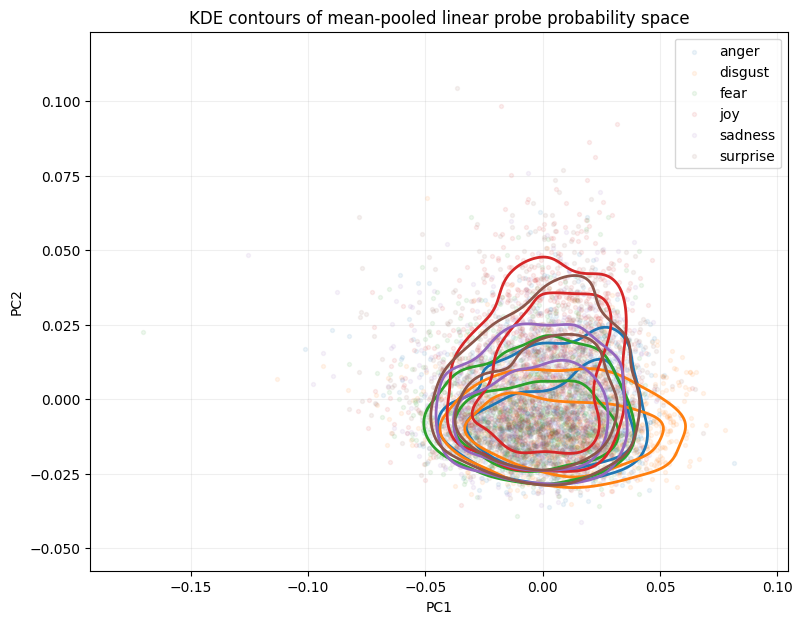


PCA of CLS linear probe decision space
Probe space shape: (6246, 6)
Explained variance ratio: [0.9963 0.0026]


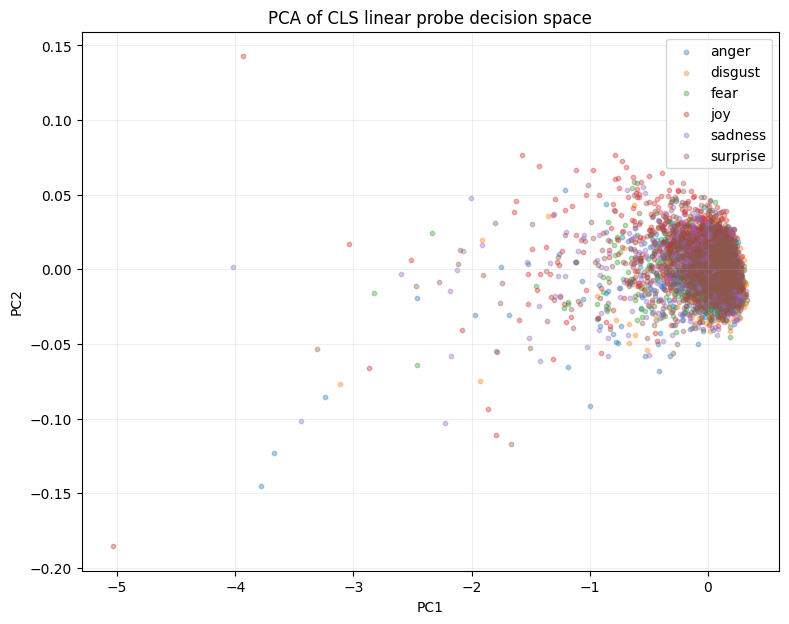


PCA of CLS linear probe probability space
Probe space shape: (6246, 6)
Explained variance ratio: [0.9558 0.0412]


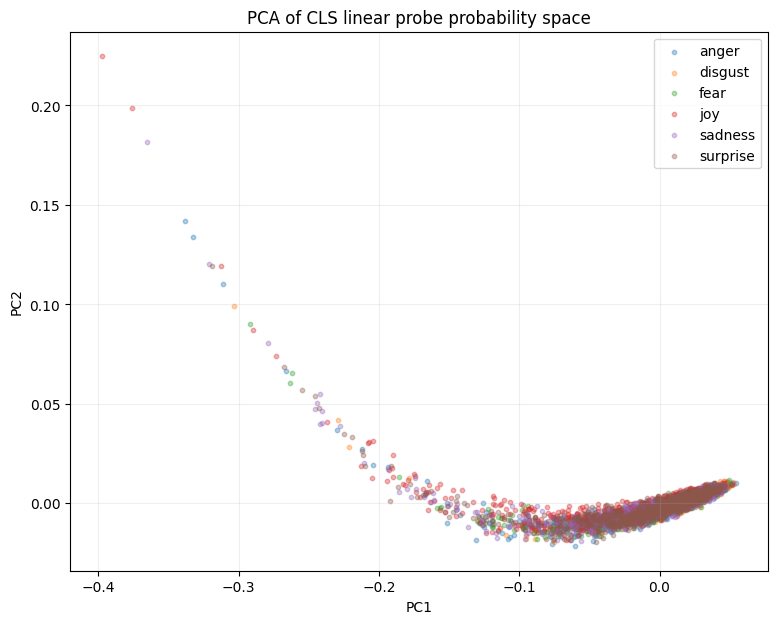


Emotion centroids in CLS linear probe decision space
Probe space shape: (6246, 6)
Explained variance ratio: [0.9963 0.0026]


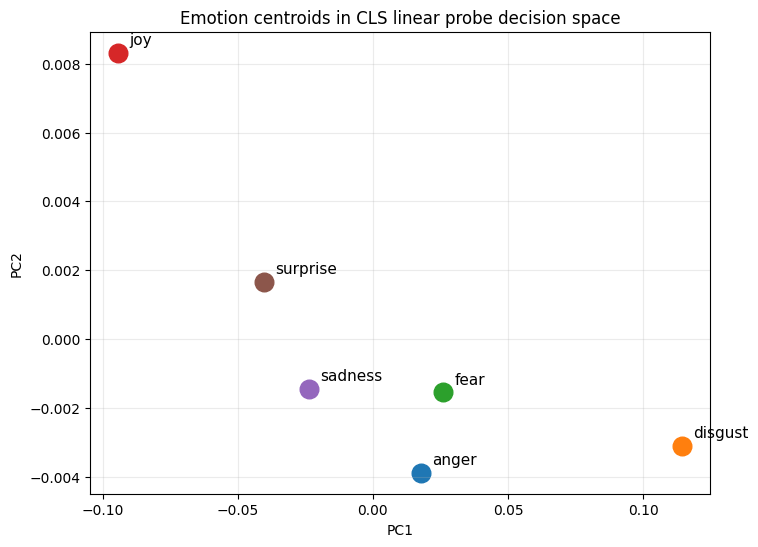


Emotion centroids in CLS linear probe probability space
Probe space shape: (6246, 6)
Explained variance ratio: [0.9558 0.0412]


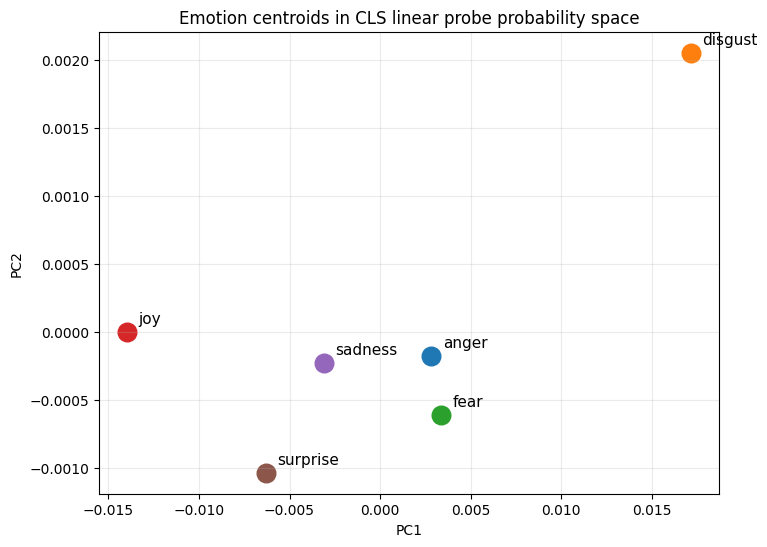


KDE contours of CLS linear probe probability space
Probe space shape: (6246, 6)
Explained variance ratio: [0.9558 0.0412]


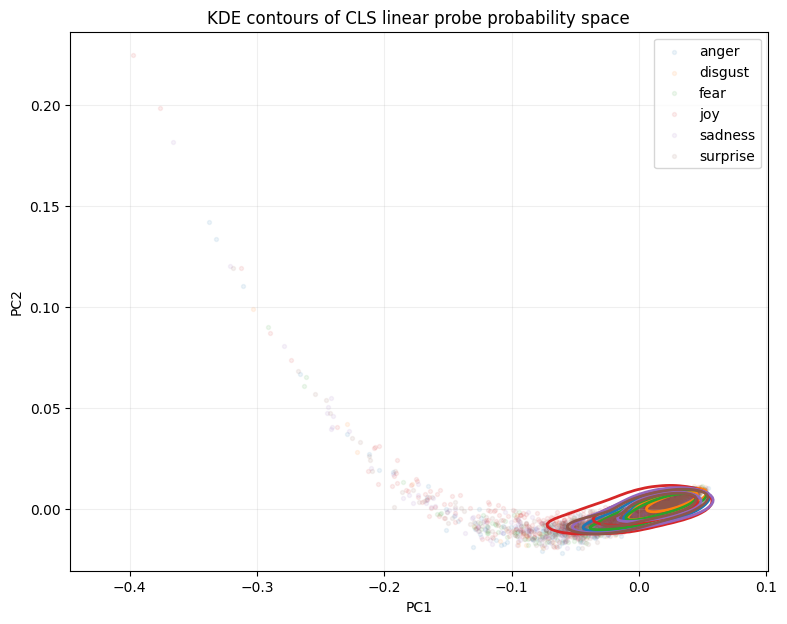

In [16]:
# probe training

mean_probe = train_probe(mean_embeddings_norm, labels, "Mean-pooled")
cls_probe = train_probe(cls_embeddings_norm, labels, "CLS")

# probe visualization

plot_probe_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "PCA of mean-pooled linear probe decision space",
    use_probabilities=False
)

# 2. PCA of probability space (all points)
plot_probe_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "PCA of mean-pooled linear probe probability space",
    use_probabilities=True
)

# 3. Centroids in decision space
plot_probe_centroids_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in mean-pooled linear probe decision space",
    use_probabilities=False
)

# 4. Centroids in probability space
plot_probe_centroids_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in mean-pooled linear probe probability space",
    use_probabilities=True
)

# 5. Paper-style KDE contours in probability space
plot_probe_kde_pca_2d(
    mean_probe,
    mean_embeddings_norm,
    labels,
    emotion_order,
    "KDE contours of mean-pooled linear probe probability space",
    use_probabilities=True
)

##### CLS!!!!!

# probe visualization

plot_probe_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "PCA of CLS linear probe decision space",
    use_probabilities=False
)

# 2. PCA of probability space (all points)
plot_probe_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "PCA of CLS linear probe probability space",
    use_probabilities=True
)

# 3. Centroids in decision space
plot_probe_centroids_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in CLS linear probe decision space",
    use_probabilities=False
)

# 4. Centroids in probability space
plot_probe_centroids_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    df,
    emotion_order,
    "Emotion centroids in CLS linear probe probability space",
    use_probabilities=True
)

# 5. Paper-style KDE contours in probability space
plot_probe_kde_pca_2d(
    cls_probe,
    cls_embeddings_norm,
    labels,
    emotion_order,
    "KDE contours of CLS linear probe probability space",
    use_probabilities=True
)



Cosine similarity between mean-pooled probe weight vectors
          anger  disgust   fear    joy  sadness  surprise
anger     1.000    0.446  0.064 -0.575   -0.167    -0.549
disgust   0.446    1.000 -0.158 -0.615   -0.439    -0.535
fear      0.064   -0.158  1.000 -0.543    0.517    -0.239
joy      -0.575   -0.615 -0.543  1.000   -0.086     0.458
sadness  -0.167   -0.439  0.517 -0.086    1.000    -0.268
surprise -0.549   -0.535 -0.239  0.458   -0.268     1.000


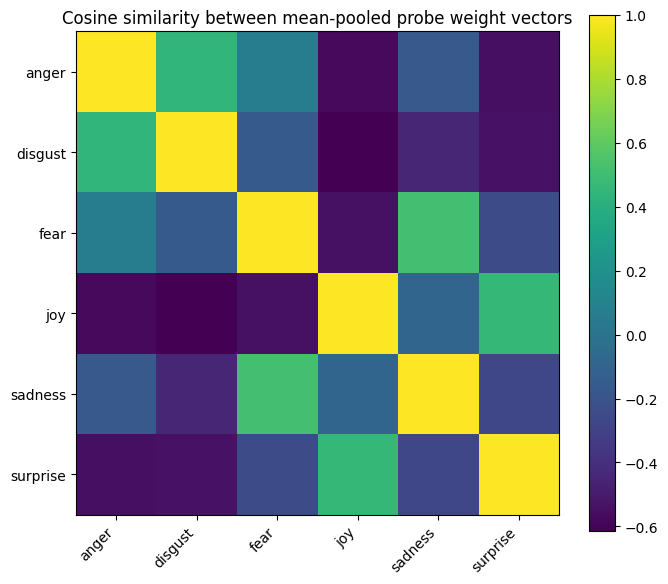


PCA of mean-pooled probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.4512 0.2959]


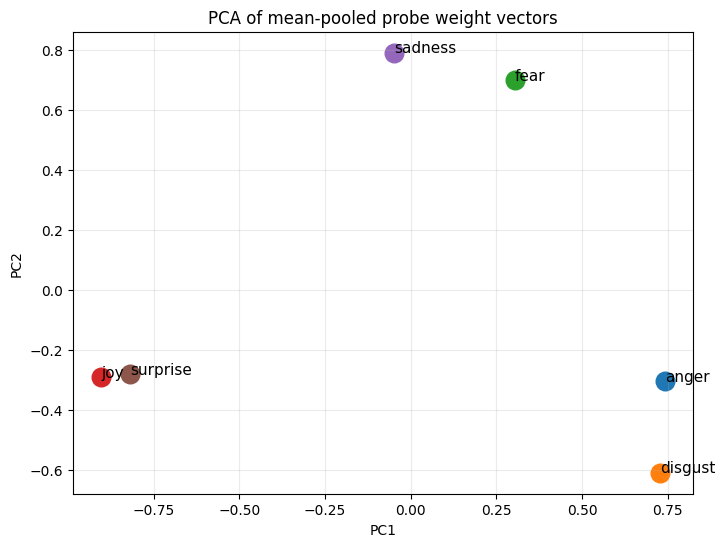


3D PCA of mean-pooled probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.4512 0.2959 0.1241]

3D PCA coordinates (per emotion):
    PC1     PC2     PC3  emotion
 0.7408 -0.3055 -0.1573    anger
 0.7268 -0.6102  0.0319  disgust
 0.3035  0.6988  0.3808     fear
-0.9037 -0.2923 -0.4224      joy
-0.0477  0.7911 -0.3458  sadness
-0.8199 -0.2820  0.5128 surprise

Desmos-friendly format:
anger: (0.7408, -0.3055, -0.1573)
disgust: (0.7268, -0.6102, 0.0319)
fear: (0.3035, 0.6988, 0.3808)
joy: (-0.9037, -0.2923, -0.4224)
sadness: (-0.0477, 0.7911, -0.3458)
surprise: (-0.8199, -0.2820, 0.5128)


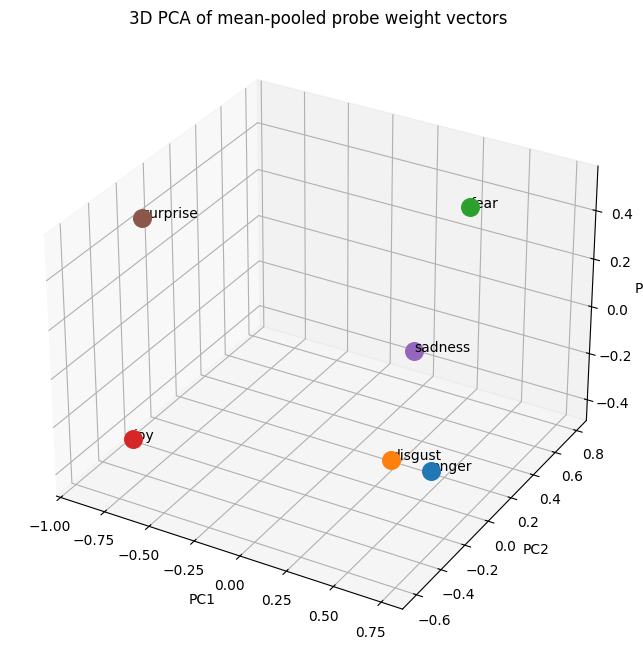


Mean-pooled probe weights vs mean-pooled class centroids
Combined shape: (12, 768)
Explained variance ratio: [0.3459 0.2969]


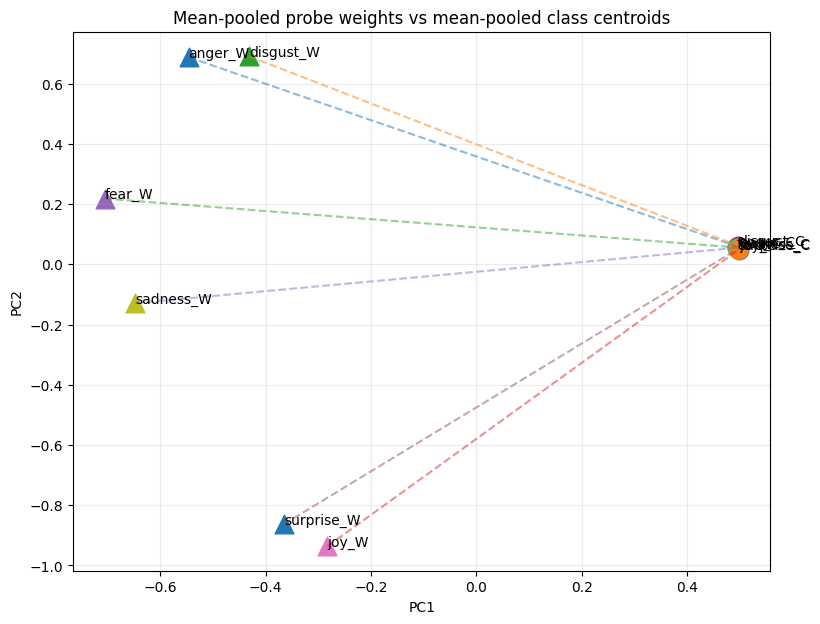


Cosine similarity between CLS probe weight vectors
          anger  disgust   fear    joy  sadness  surprise
anger     1.000    0.244  0.019 -0.475   -0.169    -0.338
disgust   0.244    1.000  0.431 -0.869   -0.695    -0.824
fear      0.019    0.431  1.000 -0.639   -0.135    -0.407
joy      -0.475   -0.869 -0.639  1.000    0.461     0.721
sadness  -0.169   -0.695 -0.135  0.461    1.000     0.325
surprise -0.338   -0.824 -0.407  0.721    0.325     1.000


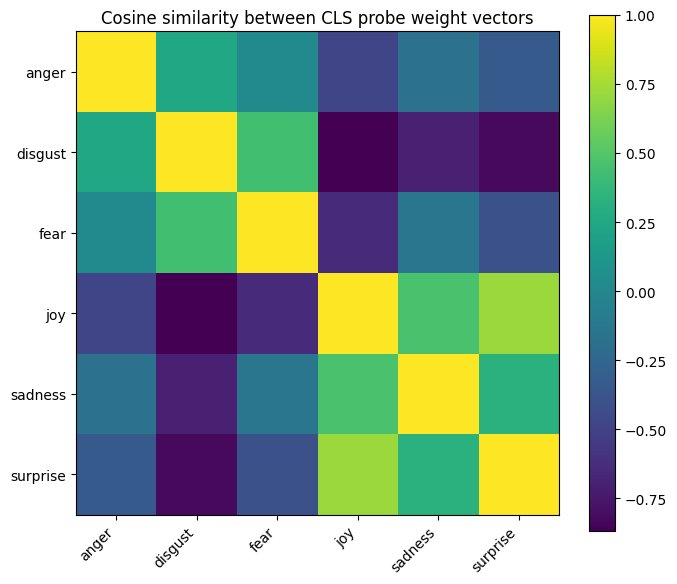


PCA of CLS probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.59   0.1719]


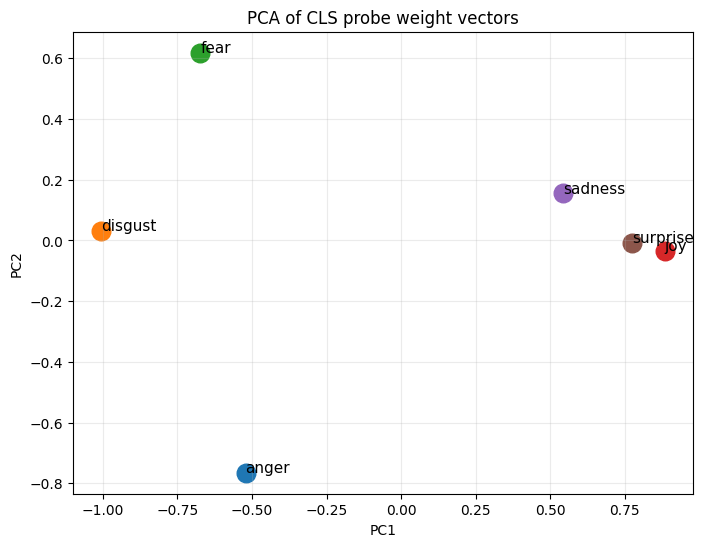


3D PCA of CLS probe weight vectors
Weight matrix shape: (6, 768)
Explained variance ratio: [0.59   0.1719 0.133 ]

3D PCA coordinates (per emotion):
    PC1     PC2     PC3  emotion
-0.5217 -0.7652 -0.2223    anger
-1.0062  0.0322  0.3546  disgust
-0.6729  0.6182 -0.1176     fear
 0.8842 -0.0340  0.2611      joy
 0.5430  0.1559 -0.6249  sadness
 0.7736 -0.0071  0.3492 surprise

Desmos-friendly format:
anger: (-0.5217, -0.7652, -0.2223)
disgust: (-1.0062, 0.0322, 0.3546)
fear: (-0.6729, 0.6182, -0.1176)
joy: (0.8842, -0.0340, 0.2611)
sadness: (0.5430, 0.1559, -0.6249)
surprise: (0.7736, -0.0071, 0.3492)


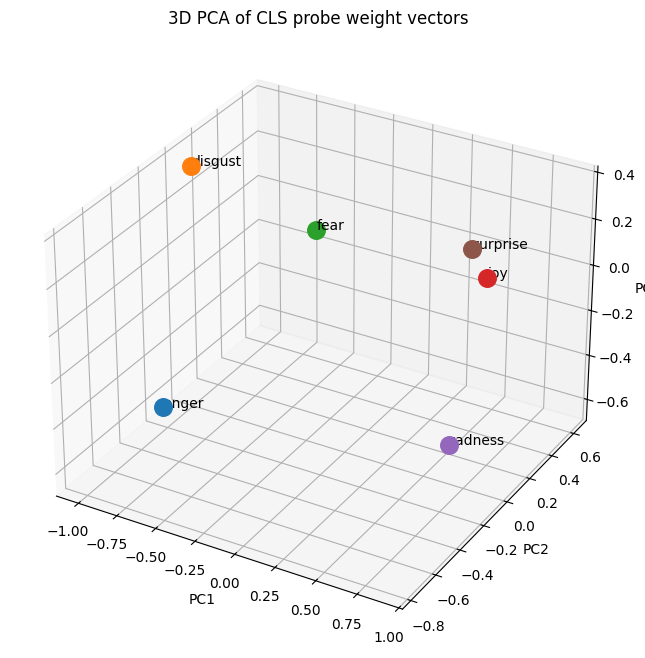


CLS probe weights vs CLS class centroids
Combined shape: (12, 768)
Explained variance ratio: [0.3927 0.3487]


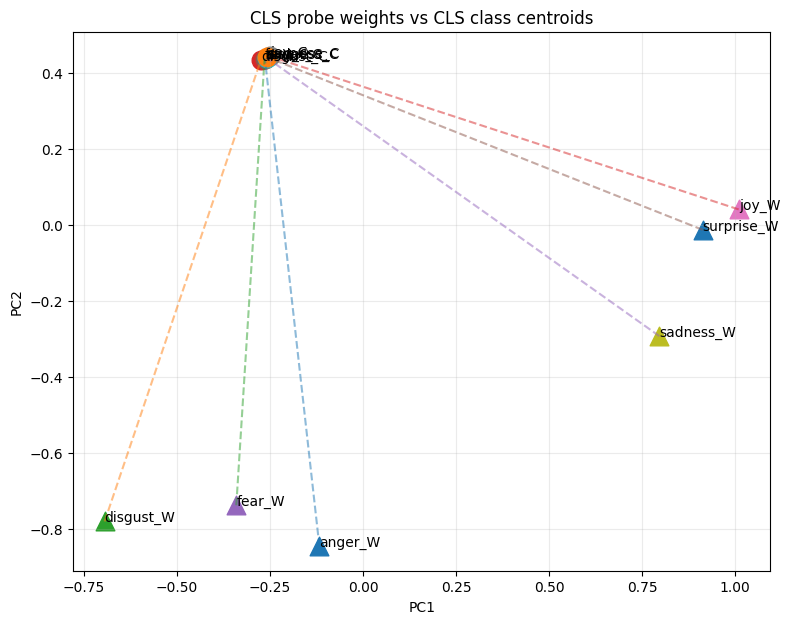

(array([[-0.11701126, -0.84623547],
        [-0.69397541, -0.78103629],
        [-0.340229  , -0.73849055],
        [ 1.00938076,  0.04036891],
        [ 0.79639171, -0.29324052],
        [ 0.91266393, -0.01333534]]),
 array([[-0.26340292,  0.43743594],
        [-0.27419378,  0.43337252],
        [-0.26428366,  0.43726803],
        [-0.25032585,  0.44366793],
        [-0.25846339,  0.43957876],
        [-0.25655113,  0.44064606]]),
 PCA(n_components=2, random_state=42))

In [17]:

# Probe weight analysis

class_order = list(mean_probe.classes_)

# Mean-pooled probe weights
plot_probe_weight_cosine_similarity(
    mean_probe,
    class_order,
    "Cosine similarity between mean-pooled probe weight vectors"
)

plot_probe_weights_pca_2d(
    mean_probe,
    class_order,
    "PCA of mean-pooled probe weight vectors"
)

plot_probe_weights_pca_3d(
    mean_probe,
    class_order,
    "3D PCA of mean-pooled probe weight vectors"
)

plot_probe_weights_vs_centroids_pca_2d(
    mean_probe,
    mean_centroids,
    class_order,
    "Mean-pooled probe weights vs mean-pooled class centroids"
)


# CLS probe weights
plot_probe_weight_cosine_similarity(
    cls_probe,
    class_order,
    "Cosine similarity between CLS probe weight vectors"
)

plot_probe_weights_pca_2d(
    cls_probe,
    class_order,
    "PCA of CLS probe weight vectors"
)

plot_probe_weights_pca_3d(
    cls_probe,
    class_order,
    "3D PCA of CLS probe weight vectors"
)

plot_probe_weights_vs_centroids_pca_2d(
    cls_probe,
    cls_centroids,
    class_order,
    "CLS probe weights vs CLS class centroids"
)

In [18]:
# example prediction and t-sne


print("\n--- Example predictions with mean-pooled probe ---")
predict_examples(example_texts, tokenizer, model, device, mean_probe, use_mean=True)

print("\n--- Example predictions with CLS probe ---")
predict_examples(example_texts, tokenizer, model, device, cls_probe, use_mean=False)

X_tsne_input = mean_embeddings_norm
y_tsne = df["emotion"].values


--- Example predictions with mean-pooled probe ---


Encoding: 100%|██████████| 1/1 [00:00<00:00,  2.44it/s]



TEXT: I am so happy and excited about this!
Predicted: joy
Top-3: [('joy', 0.212), ('surprise', 0.197), ('sadness', 0.172)]

TEXT: This is disgusting and makes me sick.
Predicted: joy
Top-3: [('joy', 0.204), ('surprise', 0.184), ('sadness', 0.172)]

TEXT: I am terrified something bad will happen.
Predicted: joy
Top-3: [('joy', 0.205), ('surprise', 0.183), ('sadness', 0.177)]

TEXT: I miss you so much and feel empty.
Predicted: joy
Top-3: [('joy', 0.216), ('surprise', 0.187), ('sadness', 0.181)]

TEXT: What a wonderful surprise!
Predicted: surprise
Top-3: [('surprise', 0.219), ('joy', 0.208), ('sadness', 0.19)]

TEXT: I am furious and cannot stand this anymore.
Predicted: joy
Top-3: [('joy', 0.202), ('surprise', 0.181), ('sadness', 0.174)]

--- Example predictions with CLS probe ---


Encoding: 100%|██████████| 1/1 [00:00<00:00, 28.11it/s]


TEXT: I am so happy and excited about this!
Predicted: joy
Top-3: [('joy', 0.219), ('surprise', 0.195), ('sadness', 0.179)]

TEXT: This is disgusting and makes me sick.
Predicted: joy
Top-3: [('joy', 0.209), ('surprise', 0.187), ('sadness', 0.18)]

TEXT: I am terrified something bad will happen.
Predicted: joy
Top-3: [('joy', 0.206), ('surprise', 0.186), ('sadness', 0.18)]

TEXT: I miss you so much and feel empty.
Predicted: joy
Top-3: [('joy', 0.235), ('surprise', 0.193), ('sadness', 0.186)]

TEXT: What a wonderful surprise!
Predicted: joy
Top-3: [('joy', 0.277), ('surprise', 0.21), ('sadness', 0.187)]

TEXT: I am furious and cannot stand this anymore.
Predicted: joy
Top-3: [('joy', 0.202), ('surprise', 0.184), ('sadness', 0.179)]


In [19]:
from datasets import load_dataset
import pandas as pd

target_emotions = ["anger", "disgust", "fear", "joy", "sadness", "surprise"]
random_state = 42

# =====================================================
# 1. LOAD BRIGHTER
# =====================================================
dfs = []

for split in ["train", "dev", "test"]:
    ds = load_dataset(
        "brighter-dataset/BRIGHTER-emotion-categories",
        "arq",
        split=split
    )
    df_part = ds.to_pandas()
    dfs.append(df_part)

brighter_df = pd.concat(dfs, ignore_index=True)
brighter_df["text"] = brighter_df["text"].astype(str)

# ensure all emotion columns exist + clean
for col in target_emotions:
    if col not in brighter_df.columns:
        brighter_df[col] = 0
    brighter_df[col] = brighter_df[col].fillna(0).astype(int)

# keep only single-label
brighter_df["n_active"] = brighter_df[target_emotions].sum(axis=1)
brighter_df = brighter_df[brighter_df["n_active"] == 1].copy()

# convert to single label
brighter_df["emotion"] = brighter_df[target_emotions].idxmax(axis=1)

brighter_df = brighter_df[["text", "emotion"]]

print("\nBRIGHTER distribution:")
print(brighter_df["emotion"].value_counts())


# second arabic

for split in ["train", "dev", "test"]:
    ds = load_dataset(
        "brighter-dataset/BRIGHTER-emotion-categories",
        "ary",
        split=split
    )
    df_part = ds.to_pandas()
    dfs.append(df_part)

brighter_df_2 = pd.concat(dfs, ignore_index=True)
brighter_df_2["text"] = brighter_df_2["text"].astype(str)

# ensure all emotion columns exist + clean
for col in target_emotions:
    if col not in brighter_df_2.columns:
        brighter_df_2[col] = 0
    brighter_df_2[col] = brighter_df_2[col].fillna(0).astype(int)

# keep only single-label
brighter_df_2["n_active"] = brighter_df_2[target_emotions].sum(axis=1)
brighter_df_2 = brighter_df_2[brighter_df_2["n_active"] == 1].copy()

# convert to single label
brighter_df_2["emotion"] = brighter_df_2[target_emotions].idxmax(axis=1)

brighter_df_2 = brighter_df_2[["text", "emotion"]]

print("\nBRIGHTER distribution 2:")
print(brighter_df_2["emotion"].value_counts())


# # =====================================================
# # 2. LOAD GOEMOTIONS (your CSV)
# # =====================================================
# go_df = pd.read_csv("goemotions_German.csv")

# go_df["text"] = go_df["text"].astype(str)
# go_df["emotion"] = go_df["emotion"].astype(str)

# # keep only target emotions (important!)
# go_df = go_df[go_df["emotion"].isin(target_emotions)]

# print("\nGoEmotions distribution:")
# print(go_df["emotion"].value_counts())


# =====================================================
# 2.1 LOAD XED (your CSV)
# =====================================================
xed_df = pd.read_csv("xed_arabic.csv")

xed_df["text"] = xed_df["text"].astype(str)
xed_df["emotion"] = xed_df["emotion"].astype(str)

# keep only target emotions (important!)
xed_df = xed_df[xed_df["emotion"].isin(target_emotions)]

print("\XED distribution:")
print(xed_df["emotion"].value_counts())


# =====================================================
# 3. COMBINE
# =====================================================
comb_df = pd.concat([brighter_df, brighter_df_2, xed_df], ignore_index=True)

print("\nCombined distribution BEFORE balancing:")
print(comb_df["emotion"].value_counts())


# =====================================================
# 4. BALANCE
# =====================================================
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []

for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced rows:", len(comb_df))
print("\nBalanced distribution:")
print(comb_df["emotion"].value_counts())


# =====================================================
# 5. FINAL OUTPUT
# =====================================================
xed_texts = comb_df["text"].tolist()
xed_labels = comb_df["emotion"].tolist()


xed_mean_embeddings, xed_cls_embeddings = encode_texts(
    xed_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

xed_mean_embeddings_norm = normalize(xed_mean_embeddings, norm="l2")
xed_cls_embeddings_norm = normalize(xed_cls_embeddings, norm="l2")

print("\nXED mean embeddings shape:", xed_mean_embeddings_norm.shape)
print("XED CLS embeddings shape:", xed_cls_embeddings_norm.shape)

print("\nMean probe classes:", mean_probe.classes_)
print("CLS probe classes:", cls_probe.classes_)

class_order = list(mean_probe.classes_)

# Split df into calibration and test
mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    xed_mean_embeddings_norm,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    xed_cls_embeddings_norm,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)



print("\nCalibration set size:", len(y_calib))
print("Test set size:", len(y_test))



# Evaluation stats
def evaluate_probe_on_single_label(embeddings, probe, gold_labels, class_order, name="Probe"):
    preds = probe.predict(embeddings)
    probs = probe.predict_proba(embeddings)

    print(f"\n=== {name} on XED test ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))
    
    
    # Top-3 accuracy
    
    top_k = 3

    # get indices of top-3 predictions per sample
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]

    # map labels to indices
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in gold_labels])

    # check if gold label is in top-k
    top_k_correct = [
        gold_idx[i] in top_k_preds[i]
        for i in range(len(gold_idx))
    ]

    top_k_acc = np.mean(top_k_correct)

    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    confidence_df = pd.DataFrame({
        "gold": gold_labels,
        "pred": preds,
        "confidence": pred_conf
    })

    per_class_conf = (
        confidence_df.groupby("gold")["confidence"]
        .agg(["mean", "std", "count"])
        .round(4)
        .rename_axis("emotion")
        .reset_index()
    )

    print("\nPer-class confidence stats:")
    print(per_class_conf.to_string(index=False))

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df,
        "confidence_stats": per_class_conf,
    }


# Baseline: uncalibrated
mean_base_results = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled mBERT (uncalibrated)"
)


BRIGHTER distribution:
emotion
sadness     331
joy         230
surprise    202
anger       130
fear         59
disgust      28
Name: count, dtype: int64

BRIGHTER distribution 2:
emotion
joy         906
anger       806
sadness     663
surprise    626
fear        189
disgust      66
Name: count, dtype: int64
\XED distribution:
emotion
anger       518
surprise    282
fear        276
sadness     244
joy         216
disgust     165
Name: count, dtype: int64

Combined distribution BEFORE balancing:
emotion
anger       1454
joy         1352
sadness     1238
surprise    1110
fear         524
disgust      259
Name: count, dtype: int64

Balanced rows: 1554

Balanced distribution:
emotion
surprise    259
disgust     259
joy         259
anger       259
sadness     259
fear        259
Name: count, dtype: int64


Encoding: 100%|██████████| 49/49 [00:12<00:00,  4.03it/s]



XED mean embeddings shape: (1554, 768)
XED CLS embeddings shape: (1554, 768)

Mean probe classes: ['anger' 'disgust' 'fear' 'joy' 'sadness' 'surprise']
CLS probe classes: ['anger' 'disgust' 'fear' 'joy' 'sadness' 'surprise']

Calibration set size: 777
Test set size: 777

=== Mean-pooled mBERT (uncalibrated) on XED test ===
Accuracy: 0.1454
Balanced accuracy: 0.1453
Macro F1: 0.1156
Weighted F1: 0.1158
Log loss: 1.8043
Top-3 accuracy: 0.4672

Classification report:
              precision    recall  f1-score   support

       anger      0.138     0.031     0.051       129
     disgust      0.113     0.264     0.159       129
        fear      0.132     0.092     0.109       130
         joy      0.217     0.423     0.286       130
     sadness      0.116     0.038     0.058       130
    surprise      0.050     0.023     0.032       129

    accuracy                          0.145       777
   macro avg      0.128     0.145     0.116       777
weighted avg      0.128     0.145     0.11

In [20]:
# =====================================================
# HUMAN-LABEL FINE-TUNED PROBE
# =====================================================

from sklearn.linear_model import LogisticRegression

def train_eval_human_probe(X_calib, X_test, y_calib, y_test, class_order, name):
    human_probe = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    human_probe.fit(X_calib, y_calib)

    preds = human_probe.predict(X_test)
    probs = human_probe.predict_proba(X_test)

    print(f"\n=== {name}: probe trained on human calibration data ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    top_k = 3
    top_k_preds = np.argsort(probs, axis=1)[:, -top_k:]
    label_to_idx = {label: i for i, label in enumerate(class_order)}
    gold_idx = np.array([label_to_idx[y] for y in y_test])
    top_k_acc = np.mean([gold_idx[i] in top_k_preds[i] for i in range(len(gold_idx))])
    print(f"Top-{top_k} accuracy:", round(top_k_acc, 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": human_probe,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


mean_human_probe_results = train_eval_human_probe(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled"
)

cls_human_probe_results = train_eval_human_probe(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    class_order,
    name="CLS"
)


=== Mean-pooled: probe trained on human calibration data ===
Accuracy: 0.2716
Balanced accuracy: 0.2711
Macro F1: 0.2478
Weighted F1: 0.248
Log loss: 1.7777
Top-3 accuracy: 0.6525

Classification report:
              precision    recall  f1-score   support

       anger      0.360     0.070     0.117       129
     disgust      0.333     0.163     0.219       129
        fear      0.200     0.308     0.242       130
         joy      0.491     0.215     0.299       130
     sadness      0.243     0.677     0.358       130
    surprise      0.357     0.194     0.251       129

    accuracy                          0.272       777
   macro avg      0.331     0.271     0.248       777
weighted avg      0.331     0.272     0.248       777

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         9        8    35   15       51        11
disgust       0       21    42    5       54         7
fear          5       20    40    3       51        11
joy           

In [21]:
from sklearn.linear_model import LogisticRegression

# =====================================================
# 6D EMOTION SUBSPACE CLASSIFIER
# =====================================================

def project_to_probe_subspace(X, probe, use_bias=False):
    W = probe.coef_.copy()
    Z = X @ W.T

    if use_bias:
        Z = Z + probe.intercept_

    return Z


def train_eval_6d_classifier(X_calib, X_test, y_calib, y_test, probe, class_order, name, use_bias=False):
    Z_calib = project_to_probe_subspace(X_calib, probe, use_bias=use_bias)
    Z_test = project_to_probe_subspace(X_test, probe, use_bias=use_bias)

    clf_6d = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    clf_6d.fit(Z_calib, y_calib)

    preds = clf_6d.predict(Z_test)
    probs = clf_6d.predict_proba(Z_test)

    print(f"\n=== {name}: Logistic Regression on 6D probe subspace ===")
    print("6D train shape:", Z_calib.shape)
    print("6D test shape:", Z_test.shape)
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": clf_6d,
        "Z_calib": Z_calib,
        "Z_test": Z_test,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


mean_6d_results = train_eval_6d_classifier(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    mean_probe,
    class_order,
    name="Mean-pooled"
)

cls_6d_results = train_eval_6d_classifier(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    cls_probe,
    class_order,
    name="CLS"
)


=== Mean-pooled: Logistic Regression on 6D probe subspace ===
6D train shape: (777, 6)
6D test shape: (777, 6)
Accuracy: 0.2291
Balanced accuracy: 0.2289
Macro F1: 0.2249
Weighted F1: 0.2249
Log loss: 1.7649

Classification report:
              precision    recall  f1-score   support

       anger      0.187     0.132     0.155       129
     disgust      0.219     0.178     0.197       129
        fear      0.141     0.162     0.151       130
         joy      0.252     0.262     0.257       130
     sadness      0.278     0.385     0.323       130
    surprise      0.282     0.256     0.268       129

    accuracy                          0.229       777
   macro avg      0.226     0.229     0.225       777
weighted avg      0.226     0.229     0.225       777

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        17       15    33   23       17        24
disgust       8       23    33   27       29         9
fear         16       32    21   20      

In [22]:
mean_6d_human_probe_results = train_eval_6d_classifier(
    mean_X_calib,
    mean_X_test,
    y_calib,
    y_test,
    mean_human_probe_results["model"],
    class_order,
    name="Mean-pooled human-probe 6D"
)

cls_6d_human_probe_results = train_eval_6d_classifier(
    cls_X_calib,
    cls_X_test,
    y_calib,
    y_test,
    cls_human_probe_results["model"],
    class_order,
    name="CLS human-probe 6D"
)


=== Mean-pooled human-probe 6D: Logistic Regression on 6D probe subspace ===
6D train shape: (777, 6)
6D test shape: (777, 6)
Accuracy: 0.2561
Balanced accuracy: 0.2555
Macro F1: 0.2189
Weighted F1: 0.2193
Log loss: 1.7648

Classification report:
              precision    recall  f1-score   support

       anger      0.269     0.054     0.090       129
     disgust      0.292     0.109     0.158       129
        fear      0.230     0.369     0.283       130
         joy      0.406     0.215     0.281       130
     sadness      0.229     0.685     0.343       130
    surprise      0.361     0.101     0.158       129

    accuracy                          0.256       777
   macro avg      0.298     0.255     0.219       777
weighted avg      0.298     0.256     0.219       777

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         7        3    39   19       57         4
disgust       2       14    48    9       53         3
fear          4       10  

In [23]:
# =====================================================
# LABEL DISAGREEMENT / ERROR INSPECTION
# =====================================================

# Recreate split with indices so we can recover the original texts
all_indices = np.arange(len(comb_df))

mean_idx_calib, mean_idx_test, _, _ = train_test_split(
    all_indices,
    xed_labels,
    test_size=0.5,
    random_state=42,
    stratify=xed_labels
)

test_texts = comb_df.iloc[mean_idx_test]["text"].tolist()
test_gold = np.array(y_test)

def inspect_strong_disagreements(X_test, probe, test_texts, gold_labels, class_order, n=30, name="Probe"):
    probs = probe.predict_proba(X_test)
    preds = probe.predict(X_test)

    pred_idx = np.argmax(probs, axis=1)
    pred_conf = probs[np.arange(len(probs)), pred_idx]

    rows = []

    for i in range(len(gold_labels)):
        if preds[i] != gold_labels[i]:
            top3_idx = np.argsort(probs[i])[::-1][:3]
            top3 = [(class_order[j], round(float(probs[i, j]), 3)) for j in top3_idx]

            rows.append({
                "text": test_texts[i],
                "gold": gold_labels[i],
                "pred": preds[i],
                "confidence": pred_conf[i],
                "top3": top3
            })

    err_df = pd.DataFrame(rows).sort_values("confidence", ascending=False)

    print(f"\n=== Strongest disagreements: {name} ===")
    print("Total errors:", len(err_df))

    for _, row in err_df.head(n).iterrows():
        print("\nTEXT:", row["text"])
        print("Gold:", row["gold"])
        print("Pred:", row["pred"])
        print("Confidence:", round(row["confidence"], 4))
        print("Top-3:", row["top3"])

    return err_df


mean_error_df = inspect_strong_disagreements(
    mean_X_test,
    mean_probe,
    test_texts,
    test_gold,
    class_order,
    n=30,
    name="Mean-pooled probe"
)

cls_error_df = inspect_strong_disagreements(
    cls_X_test,
    cls_probe,
    test_texts,
    test_gold,
    class_order,
    n=30,
    name="CLS probe"
)


=== Strongest disagreements: Mean-pooled probe ===
Total errors: 664

TEXT: حسنا فعلت
Gold: joy
Pred: fear
Confidence: 0.2216
Top-3: [('fear', 0.222), ('sadness', 0.212), ('surprise', 0.206)]

TEXT: سأمرض
Gold: disgust
Pred: fear
Confidence: 0.2178
Top-3: [('fear', 0.218), ('sadness', 0.207), ('surprise', 0.195)]

TEXT: انت نجم
Gold: joy
Pred: fear
Confidence: 0.2174
Top-3: [('fear', 0.217), ('sadness', 0.203), ('surprise', 0.195)]

TEXT: لا تلمسيني.
Gold: disgust
Pred: fear
Confidence: 0.2164
Top-3: [('fear', 0.216), ('sadness', 0.203), ('surprise', 0.189)]

TEXT: كان؟
Gold: surprise
Pred: fear
Confidence: 0.2161
Top-3: [('fear', 0.216), ('surprise', 0.201), ('sadness', 0.2)]

TEXT: -هذا غير جيد للصورة؟
Gold: fear
Pred: surprise
Confidence: 0.2157
Top-3: [('surprise', 0.216), ('sadness', 0.2), ('fear', 0.191)]

TEXT: إسمع.
Gold: anger
Pred: sadness
Confidence: 0.2141
Top-3: [('sadness', 0.214), ('fear', 0.211), ('surprise', 0.21)]

TEXT: عاهرة!
Gold: anger
Pred: fear
Confidence: 0.21

In [24]:

# Projection classifier: cosine to probe weights

mean_weight_preds, mean_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_weight_results = evaluate_simple_classifier(
    y_test,
    mean_weight_preds,
    mean_weight_scores,
    class_order,
    name="Mean-pooled XLM-R (cosine to probe weights)"
)

cls_weight_preds, cls_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_weight_results = evaluate_simple_classifier(
    y_test,
    cls_weight_preds,
    cls_weight_scores,
    class_order,
    name="CLS XLM-R (cosine to probe weights)"
)


# Prototype classifier: nearest centroid

mean_proto_preds, mean_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proto_preds,
    mean_proto_scores,
    class_order,
    name="Mean-pooled XLM-R (prototype classifier)"
)

cls_proto_preds, cls_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proto_preds,
    cls_proto_scores,
    class_order,
    name="CLS XLM-R (prototype classifier)"
)




=== Mean-pooled XLM-R (cosine to probe weights) on XED test ===
Accuracy: 0.1441
Balanced accuracy: 0.1443
Macro F1: 0.0959
Weighted F1: 0.096
Log loss: 1.794

Classification report:
              precision    recall  f1-score   support

       anger      0.150     0.535     0.235       129
     disgust      0.000     0.000     0.000       129
        fear      0.103     0.031     0.047       130
         joy      0.203     0.115     0.147       130
     sadness      0.121     0.185     0.146       130
    surprise      0.000     0.000     0.000       129

    accuracy                          0.144       777
   macro avg      0.096     0.144     0.096       777
weighted avg      0.096     0.144     0.096       777

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        69        2     9    9       40         0
disgust      58        0    12   20       39         0
fear         60        1     4   18       47         0
joy          83        2     6   15

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

In [25]:
### TEST

example_texts = [
    "I just got promoted at work, I can't believe it!",
    "This is absolutely disgusting, I feel sick.",
    "I'm really scared about what might happen tomorrow.",
    "I miss you so much, everything feels empty without you.",
    "Wow, I did not expect that at all!"
]

def print_topk_linear_predictions(
    texts,
    tokenizer,
    model,
    device,
    probe,
    class_order,
    use_mean=True,
    top_k=3
):
    # Encode
    mean_embs, cls_embs = encode_texts(
        texts,
        tokenizer,
        model,
        device,
        batch_size=8,
        max_length=MAX_LENGTH
    )

    if use_mean:
        X = normalize(mean_embs, norm="l2")
    else:
        X = normalize(cls_embs, norm="l2")

    # Get linear scores
    _, scores = predict_with_linear_scores(
        X,
        probe,
        class_order,
        normalize_inputs=False
    )

    print("\n=== Top-k predictions (linear scores x·w + b) ===\n")

    for i, text in enumerate(texts):
        score_vec = scores[i]

        # sort descending
        top_indices = np.argsort(score_vec)[::-1][:top_k]

        print(f"Text: {text}")
        for rank, idx in enumerate(top_indices, 1):
            emotion = class_order[idx]
            score = score_vec[idx]
            print(f"  {rank}. {emotion:10s} | score = {score:.4f}")
        print()
        
    _, scores = predict_with_weight_cosine(
        X,
        probe,
        class_order
    )

    print("\n=== Top-k predictions (just linear scores x·w) ===\n")

    for i, text in enumerate(texts):
        score_vec = scores[i]

        # sort descending
        top_indices = np.argsort(score_vec)[::-1][:top_k]

        print(f"Text: {text}")
        for rank, idx in enumerate(top_indices, 1):
            emotion = class_order[idx]
            score = score_vec[idx]
            print(f"  {rank}. {emotion:10s} | score = {score:.4f}")
        print()
        
print_topk_linear_predictions(
    example_texts,
    tokenizer,
    model,
    device,
    mean_probe,
    class_order,
    use_mean=True
)

Encoding: 100%|██████████| 1/1 [00:00<00:00,  2.23it/s]


=== Top-k predictions (linear scores x·w + b) ===

Text: I just got promoted at work, I can't believe it!
  1. joy        | score = 0.2119
  2. surprise   | score = 0.1117
  3. sadness    | score = 0.0427

Text: This is absolutely disgusting, I feel sick.
  1. joy        | score = 0.2261
  2. surprise   | score = 0.1399
  3. sadness    | score = 0.0413

Text: I'm really scared about what might happen tomorrow.
  1. joy        | score = 0.2335
  2. surprise   | score = 0.1163
  3. sadness    | score = 0.0373

Text: I miss you so much, everything feels empty without you.
  1. joy        | score = 0.3057
  2. surprise   | score = 0.1179
  3. sadness    | score = 0.0778

Text: Wow, I did not expect that at all!
  1. joy        | score = 0.2721
  2. surprise   | score = 0.1779
  3. sadness    | score = 0.0816


=== Top-k predictions (just linear scores x·w) ===

Text: I just got promoted at work, I can't believe it!
  1. joy        | score = 0.0323
  2. sadness    | score = 0.0266
  3. sur

In [26]:
def compute_label_centroids(X, y, class_order):
    y = np.array(y)
    centroids = []
    for emotion in class_order:
        mask = y == emotion
        centroids.append(X[mask].mean(axis=0))
    return normalize(np.vstack(centroids), norm="l2")


# Human-labeled English centroids

mean_human_centroids = compute_label_centroids(
    mean_X_calib,
    y_calib,
    class_order
)

# CHINESE

In [27]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_chinese.csv", "xed_tw.csv", "brighter_chinese.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 5426

Original German class distribution:
emotion
anger       2144
joy         1732
sadness      830
surprise     311
disgust      208
fear         201
Name: count, dtype: int64

Balanced German rows: 1206

Balanced German class distribution:
emotion
anger       201
disgust     201
joy         201
fear        201
sadness     201
surprise    201
Name: count, dtype: int64


Encoding: 100%|██████████| 38/38 [00:12<00:00,  3.12it/s]


German mean embeddings shape: (1206, 768)
German CLS embeddings shape: (1206, 768)

German calibration set size: 603
German test set size: 603


In [28]:

# Helpers

def softmax_np(scores):
    scores = scores - scores.max(axis=1, keepdims=True)
    exp_scores = np.exp(scores)
    return exp_scores / exp_scores.sum(axis=1, keepdims=True)


def evaluate_probe_on_single_label(embeddings, probe, gold_labels, class_order, name="Probe"):
    preds = probe.predict(embeddings)
    probs = probe.predict_proba(embeddings)

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(gold_labels, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(gold_labels, preds), 4))
    print("Macro F1:", round(f1_score(gold_labels, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(gold_labels, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(gold_labels, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(gold_labels, preds, digits=3))

    cm = confusion_matrix(gold_labels, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)

    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


from scipy.optimize import minimize
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score
import numpy as np

def fit_bias_only(
    X_calib,
    y_calib,
    probe,
    class_order,
    l2_values=(0.0, 1e-4, 1e-3, 1e-2, 1e-1, 1.0),
    random_state=42,
):
    """
    Freeze probe weights W, tune L2 regularization, and learn only bias b.
    L2 is selected using an internal split of the calibration set.
    """
    W = probe.coef_.copy()
    old_b = probe.intercept_.copy()

    label_to_idx = {label: i for i, label in enumerate(class_order)}

    X_train, X_val, y_train, y_val = train_test_split(
        X_calib,
        y_calib,
        test_size=0.3,
        random_state=random_state,
        stratify=y_calib,
    )

    y_train_idx = np.array([label_to_idx[y] for y in y_train])

    def softmax_np(scores):
        scores = scores - scores.max(axis=1, keepdims=True)
        exp_scores = np.exp(scores)
        return exp_scores / exp_scores.sum(axis=1, keepdims=True)

    def fit_for_l2(l2):
        def objective(b):
            scores = X_train @ W.T + b
            probs = softmax_np(scores)

            nll = -np.mean(
                np.log(probs[np.arange(len(y_train_idx)), y_train_idx] + 1e-12)
            )

            penalty = l2 * np.sum((b - old_b) ** 2)

            return nll + penalty

        result = minimize(
            objective,
            x0=old_b,
            method="BFGS",
        )

        return result.x

    best_l2 = None
    best_f1 = -1
    best_b = None

    print("\nBias-only calibration L2 search:")

    for l2 in l2_values:
        candidate_b = fit_for_l2(l2)

        val_scores = X_val @ W.T + candidate_b
        val_pred_idx = np.argmax(val_scores, axis=1)
        val_preds = np.array([class_order[i] for i in val_pred_idx])

        val_f1 = f1_score(y_val, val_preds, average="macro")

        print(f"  l2={l2:<8} validation_macro_f1={val_f1:.4f}")

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_l2 = l2
            best_b = candidate_b

    print(f"Best l2: {best_l2} | validation_macro_f1={best_f1:.4f}")

    # Refit final bias on the full calibration set using best L2
    y_calib_idx = np.array([label_to_idx[y] for y in y_calib])

    def final_objective(b):
        scores = X_calib @ W.T + b
        probs = softmax_np(scores)

        nll = -np.mean(
            np.log(probs[np.arange(len(y_calib_idx)), y_calib_idx] + 1e-12)
        )

        penalty = best_l2 * np.sum((b - old_b) ** 2)

        return nll + penalty

    final_result = minimize(
        final_objective,
        x0=old_b,
        method="BFGS",
    )

    return final_result.x


def evaluate_fixed_weights_new_bias(X_test, y_test, probe, new_b, class_order, name):
    W = probe.coef_.copy()
    scores = X_test @ W.T + new_b
    probs = softmax_np(scores)

    pred_idx = np.argmax(probs, axis=1)
    preds = np.array([class_order[i] for i in pred_idx])

    print(f"\n=== {name} ===")
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }


def compute_label_centroids(X, y, class_order):
    y = np.array(y)
    centroids = []
    for emotion in class_order:
        mask = y == emotion
        centroids.append(X[mask].mean(axis=0))
    return normalize(np.vstack(centroids), norm="l2")


def fit_procrustes_from_centroids(X_calib, y_calib, target_centroids, class_order):
    """
    Learns an orthogonal rotation from German calibration centroids
    to English weak-label centroids.
    """
    source_centroids = compute_label_centroids(X_calib, y_calib, class_order)

    R, scale = orthogonal_procrustes(source_centroids, target_centroids)

    print("\nProcrustes scale:", round(scale, 4))

    return R


def apply_rotation(X, R):
    return normalize(X @ R, norm="l2")

In [29]:
from sklearn.linear_model import LogisticRegression

def project_to_probe_subspace(X, probe):
    """
    Projects embeddings into the 6D English probe-weight emotion space:
        Z = X @ W.T
    """
    W = probe.coef_.copy()
    return X @ W.T


def evaluate_6d_logreg(Z_calib, Z_test, y_calib, y_test, class_order, name):
    clf_6d = LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    )

    clf_6d.fit(Z_calib, y_calib)

    preds = clf_6d.predict(Z_test)
    probs = clf_6d.predict_proba(Z_test)

    print(f"\n=== {name}: LogReg on 6D projected emotion space ===")
    print("6D train shape:", Z_calib.shape)
    print("6D test shape:", Z_test.shape)
    print("Accuracy:", round(accuracy_score(y_test, preds), 4))
    print("Balanced accuracy:", round(balanced_accuracy_score(y_test, preds), 4))
    print("Macro F1:", round(f1_score(y_test, preds, average="macro"), 4))
    print("Weighted F1:", round(f1_score(y_test, preds, average="weighted"), 4))
    print("Log loss:", round(log_loss(y_test, probs, labels=class_order), 4))

    print("\nClassification report:")
    print(classification_report(y_test, preds, digits=3))

    cm = confusion_matrix(y_test, preds, labels=class_order)
    cm_df = pd.DataFrame(cm, index=class_order, columns=class_order)
    print("Confusion matrix:")
    print(cm_df.to_string())

    return {
        "model": clf_6d,
        "preds": preds,
        "probs": probs,
        "confusion_matrix": cm_df
    }

In [30]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])



=== Mean-pooled English probe directly on German ===
Accuracy: 0.2139
Balanced accuracy: 0.2133
Macro F1: 0.1306
Weighted F1: 0.1308
Log loss: 1.7724

Classification report:
              precision    recall  f1-score   support

       anger      0.000     0.000     0.000       100
     disgust      0.206     0.070     0.104       100
        fear      0.333     0.089     0.141       101
         joy      0.204     0.960     0.336       101
     sadness      0.000     0.000     0.000       101
    surprise      0.276     0.160     0.203       100

    accuracy                          0.214       603
   macro avg      0.170     0.213     0.131       603
weighted avg      0.170     0.214     0.131       603

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         0       10     2   85        1         2
disgust       2        7     4   70        1        16
fear          0        8     9   69        0        15
joy           0        2     0   97        0

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


  l2=0.0      validation_macro_f1=0.2140
  l2=0.0001   validation_macro_f1=0.2140
  l2=0.001    validation_macro_f1=0.2127
  l2=0.01     validation_macro_f1=0.2206
  l2=0.1      validation_macro_f1=0.1972
  l2=1.0      validation_macro_f1=0.1580
Best l2: 0.01 | validation_macro_f1=0.2206

Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.1527
  l2=0.0001   validation_macro_f1=0.1527
  l2=0.001    validation_macro_f1=0.1433
  l2=0.01     validation_macro_f1=0.1580
  l2=0.1      validation_macro_f1=0.1321
  l2=1.0      validation_macro_f1=0.1371
Best l2: 0.01 | validation_macro_f1=0.1580

Original mean bias:
anger      -0.0548
disgust    -0.0154
fear       -0.0186
joy         0.0239
sadness    -0.0396
surprise    0.1044
dtype: float64

German-calibrated mean bias:
anger      -0.0355
disgust     0.0021
fear        0.0795
joy        -0.1131
sadness     0.0107
surprise    0.0564
dtype: float64

Original CLS bias:
anger       0.1952
disgust    -0.0837
fear       -0.0496
jo

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

Weighted F1: 0.118
Log loss: 1.7917

Classification report:
              precision    recall  f1-score   support

       anger      0.000     0.000     0.000       100
     disgust      0.188     0.030     0.052       100
        fear      0.267     0.228     0.246       101
         joy      0.205     0.960     0.337       101
     sadness      0.500     0.010     0.019       101
    surprise      0.167     0.030     0.051       100

    accuracy                          0.211       603
   macro avg      0.221     0.210     0.118       603
weighted avg      0.222     0.211     0.118       603

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         0        8     5   87        0         0
disgust       5        3    17   68        1         6
fear          1        1    23   71        0         5
joy           0        1     2   97        0         1
sadness       0        1     7   89        1         3
surprise      1        2    32   62        0     

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

  l2=0.01     validation_macro_f1=0.4087
  l2=0.1      validation_macro_f1=0.4071
  l2=1.0      validation_macro_f1=0.4119
Best l2: 1.0 | validation_macro_f1=0.4119

Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.2188
  l2=0.0001   validation_macro_f1=0.2188
  l2=0.001    validation_macro_f1=0.2160
  l2=0.01     validation_macro_f1=0.2239
  l2=0.1      validation_macro_f1=0.2569
  l2=1.0      validation_macro_f1=0.2869
Best l2: 1.0 | validation_macro_f1=0.2869

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.3914
Balanced accuracy: 0.3914
Macro F1: 0.349
Weighted F1: 0.3488
Log loss: 1.7403

Classification report:
              precision    recall  f1-score   support

       anger      0.578     0.590     0.584       100
     disgust      0.323     0.210     0.255       100
        fear      1.000     0.010     0.020       101
         joy      0.491     0.812     0.612       101
     sadness      0.241     0.327     0.277       101
    su

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

# ESTONIAN

In [31]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_estonian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
# target_n = comb_df["emotion"].value_counts().min()
target_n = 20

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 674

Original German class distribution:
emotion
anger       205
fear        106
joy         105
surprise    102
sadness     101
disgust      55
Name: count, dtype: int64

Balanced German rows: 120

Balanced German class distribution:
emotion
fear        20
anger       20
disgust     20
joy         20
surprise    20
sadness     20
Name: count, dtype: int64


Encoding: 100%|██████████| 4/4 [00:01<00:00,  3.97it/s]


German mean embeddings shape: (120, 768)
German CLS embeddings shape: (120, 768)

German calibration set size: 60
German test set size: 60


In [32]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.2
Balanced accuracy: 0.2
Macro F1: 0.1367
Weighted F1: 0.1367
Log loss: 1.7976

Classification report:
              precision    recall  f1-score   support

       anger      0.000     0.000     0.000        10
     disgust      0.000     0.000     0.000        10
        fear      0.267     0.400     0.320        10
         joy      0.192     0.500     0.278        10
     sadness      0.000     0.000     0.000        10
    surprise      0.176     0.300     0.222        10

    accuracy                          0.200        60
   macro avg      0.106     0.200     0.137        60
weighted avg      0.106     0.200     0.137        60

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         0        0     4    2        0         4
disgust       0        0     3    5        0         2
fear          0        0     4    5        0         1
joy           0        0     2    5        0      

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 5.9983

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.2
Balanced accuracy: 0.2
Macro F1: 0.1387
Weighted F1: 0.1387
Log loss: 1.821

Classification report:
              precision    recall  f1-score   support

       anger      0.000     0.000     0.000        10
     disgust      0.172     0.500     0.256        10
        fear      0.000     0.000     0.000        10
         joy      0.211     0.400     0.276        10
     sadness      0.000     0.000     0.000        10
    surprise      0.300     0.300     0.300        10

    accuracy                          0.200        60
   macro avg      0.114     0.200     0.139        60
weighted avg      0.114     0.200     0.139        60

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         0        4     0    2        1         3
disgust       0        5     1    3        0         1
fear          0        5     0    3        0         2
joy           0

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

  l2=1.0      validation_macro_f1=0.3393
Best l2: 0.0 | validation_macro_f1=0.5275

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.1833
Balanced accuracy: 0.1833
Macro F1: 0.1473
Weighted F1: 0.1473
Log loss: 1.8202

Classification report:
              precision    recall  f1-score   support

       anger      0.000     0.000     0.000        10
     disgust      0.192     0.500     0.278        10
        fear      0.500     0.100     0.167        10
         joy      0.125     0.200     0.154        10
     sadness      0.000     0.000     0.000        10
    surprise      0.273     0.300     0.286        10

    accuracy                          0.183        60
   macro avg      0.182     0.183     0.147        60
weighted avg      0.182     0.183     0.147        60

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         0        4     0    2        1         3
disgust       0        5     1    3        0         1
fear    

# RUSSIAN

In [33]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_russian.csv", "brighter_russian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 4540

Original German class distribution:
emotion
anger       1043
joy         1015
fear         734
sadness      724
surprise     612
disgust      412
Name: count, dtype: int64

Balanced German rows: 2472

Balanced German class distribution:
emotion
fear        412
surprise    412
sadness     412
joy         412
anger       412
disgust     412
Name: count, dtype: int64


Encoding: 100%|██████████| 78/78 [00:12<00:00,  6.22it/s]


German mean embeddings shape: (2472, 768)
German CLS embeddings shape: (2472, 768)

German calibration set size: 1236
German test set size: 1236


In [34]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.1578
Balanced accuracy: 0.1578
Macro F1: 0.0977
Weighted F1: 0.0977
Log loss: 1.7889

Classification report:
              precision    recall  f1-score   support

       anger      1.000     0.005     0.010       206
     disgust      0.000     0.000     0.000       206
        fear      0.121     0.087     0.101       206
         joy      0.156     0.670     0.253       206
     sadness      0.055     0.015     0.023       206
    surprise      0.240     0.170     0.199       206

    accuracy                          0.158      1236
   macro avg      0.262     0.158     0.098      1236
weighted avg      0.262     0.158     0.098      1236

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         1        0    33  141       11        20
disgust       0        0    14  165        7        20
fear          0        0    18  154       18        16
joy           0        0    19  138        5

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 5.9996

Procrustes scale: 5.9998

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.3058
Balanced accuracy: 0.3058
Macro F1: 0.2712
Weighted F1: 0.2712
Log loss: 1.7403

Classification report:
              precision    recall  f1-score   support

       anger      0.419     0.063     0.110       206
     disgust      0.222     0.718     0.339       206
        fear      0.422     0.092     0.151       206
         joy      0.531     0.335     0.411       206
     sadness      0.967     0.141     0.246       206
    surprise      0.299     0.485     0.370       206

    accuracy                          0.306      1236
   macro avg      0.477     0.306     0.271      1236
weighted avg      0.477     0.306     0.271      1236

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        13      110    11   17        0        55
disgust       8      148     2    3        0        45
fear          3      110    19   12  

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

  l2=0.0001   validation_macro_f1=0.3189
  l2=0.001    validation_macro_f1=0.3190
  l2=0.01     validation_macro_f1=0.3166
  l2=0.1      validation_macro_f1=0.3118
  l2=1.0      validation_macro_f1=0.3081
Best l2: 0.001 | validation_macro_f1=0.3190

Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.2023
  l2=0.0001   validation_macro_f1=0.2023
  l2=0.001    validation_macro_f1=0.2023
  l2=0.01     validation_macro_f1=0.2024
  l2=0.1      validation_macro_f1=0.2061
  l2=1.0      validation_macro_f1=0.2236
Best l2: 1.0 | validation_macro_f1=0.2236

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.3309
Balanced accuracy: 0.3309
Macro F1: 0.3102
Weighted F1: 0.3102
Log loss: 1.7401

Classification report:
              precision    recall  f1-score   support

       anger      0.321     0.087     0.137       206
     disgust      0.239     0.694     0.356       206
        fear      0.386     0.165     0.231       206
         joy      0.516     0

# SWAHILI

In [35]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["brighter_swahili.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 3965

Original German class distribution:
emotion
surprise    1103
joy          951
sadness      675
anger        623
disgust      434
fear         179
Name: count, dtype: int64

Balanced German rows: 1074

Balanced German class distribution:
emotion
joy         179
fear        179
disgust     179
surprise    179
anger       179
sadness     179
Name: count, dtype: int64


Encoding: 100%|██████████| 34/34 [00:07<00:00,  4.53it/s]


German mean embeddings shape: (1074, 768)
German CLS embeddings shape: (1074, 768)

German calibration set size: 537
German test set size: 537


In [36]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.2216
Balanced accuracy: 0.2215
Macro F1: 0.1765
Weighted F1: 0.1766
Log loss: 1.7806

Classification report:
              precision    recall  f1-score   support

       anger      0.412     0.079     0.132        89
     disgust      0.667     0.022     0.043        89
        fear      0.164     0.233     0.193        90
         joy      0.242     0.444     0.314        90
     sadness      0.364     0.044     0.079        90
    surprise      0.211     0.506     0.298        89

    accuracy                          0.222       537
   macro avg      0.343     0.221     0.177       537
weighted avg      0.343     0.222     0.177       537

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         7        0    25   20        2        35
disgust       4        2    22   24        2        35
fear          3        0    21   29        0        37
joy           2        0    15   40        1

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 6.0002

Procrustes scale: 6.0001

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.2477
Balanced accuracy: 0.2476
Macro F1: 0.2232
Weighted F1: 0.2234
Log loss: 1.7706

Classification report:
              precision    recall  f1-score   support

       anger      0.133     0.022     0.038        89
     disgust      0.202     0.393     0.267        89
        fear      0.250     0.156     0.192        90
         joy      0.290     0.467     0.357        90
     sadness      0.271     0.178     0.215        90
    surprise      0.270     0.270     0.270        89

    accuracy                          0.248       537
   macro avg      0.236     0.248     0.223       537
weighted avg      0.236     0.248     0.223       537

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         2       31    11   23       12        10
disgust       1       35     7   16        7        23
fear          4       28    14   27  

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.2108
  l2=0.0001   validation_macro_f1=0.2108
  l2=0.001    validation_macro_f1=0.2179
  l2=0.01     validation_macro_f1=0.2422
  l2=0.1      validation_macro_f1=0.2168
  l2=1.0      validation_macro_f1=0.2077
Best l2: 0.01 | validation_macro_f1=0.2422

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.2458
Balanced accuracy: 0.2457
Macro F1: 0.2218
Weighted F1: 0.222
Log loss: 1.7706

Classification report:
              precision    recall  f1-score   support

       anger      0.133     0.022     0.038        89
     disgust      0.201     0.393     0.266        89
        fear      0.255     0.156     0.193        90
         joy      0.285     0.456     0.350        90
     sadness      0.271     0.178     0.215        90
    surprise      0.267     0.270     0.268        89

    accuracy                          0.246       537
   macro avg      0.235     0.246     0.222       537
weighte

# UKRANIAN

In [37]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["brighter_ukranian.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 3583

Original German class distribution:
emotion
joy         1185
sadness      936
surprise     527
fear         479
anger        250
disgust      206
Name: count, dtype: int64

Balanced German rows: 1236

Balanced German class distribution:
emotion
disgust     206
joy         206
surprise    206
anger       206
fear        206
sadness     206
Name: count, dtype: int64


Encoding: 100%|██████████| 39/39 [00:06<00:00,  5.79it/s]



German mean embeddings shape: (1236, 768)
German CLS embeddings shape: (1236, 768)

German calibration set size: 618
German test set size: 618


In [38]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.1667
Balanced accuracy: 0.1667
Macro F1: 0.0867
Weighted F1: 0.0867
Log loss: 1.7861

Classification report:
              precision    recall  f1-score   support

       anger      0.000     0.000     0.000       103
     disgust      0.000     0.000     0.000       103
        fear      0.048     0.010     0.016       103
         joy      0.164     0.835     0.274       103
     sadness      0.081     0.029     0.043       103
    surprise      0.361     0.126     0.187       103

    accuracy                          0.167       618
   macro avg      0.109     0.167     0.087       618
weighted avg      0.109     0.167     0.087       618

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         0        0     6   87        5         5
disgust       0        0     7   89        4         3
fear          0        0     1   94        7         1
joy           0        0     1   86        7

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Procrustes scale: 6.0002

Procrustes scale: 5.9998

=== Mean-pooled English probe on Procrustes-aligned German ===
Accuracy: 0.3754
Balanced accuracy: 0.3754
Macro F1: 0.3627
Weighted F1: 0.3627
Log loss: 1.7577

Classification report:
              precision    recall  f1-score   support

       anger      0.440     0.107     0.172       103
     disgust      0.433     0.505     0.466       103
        fear      0.352     0.495     0.411       103
         joy      0.632     0.417     0.503       103
     sadness      0.316     0.233     0.268       103
    surprise      0.277     0.495     0.355       103

    accuracy                          0.375       618
   macro avg      0.408     0.375     0.363       618
weighted avg      0.408     0.375     0.363       618

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger        11       24    23    1       10        34
disgust       3       52    13    3        5        27
fear          3        7    51    8  

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.4216
  l2=0.0001   validation_macro_f1=0.4216
  l2=0.001    validation_macro_f1=0.4216
  l2=0.01     validation_macro_f1=0.4270
  l2=0.1      validation_macro_f1=0.4277
  l2=1.0      validation_macro_f1=0.4283
Best l2: 1.0 | validation_macro_f1=0.4283

Bias-only calibration L2 search:
  l2=0.0      validation_macro_f1=0.2445
  l2=0.0001   validation_macro_f1=0.2445
  l2=0.001    validation_macro_f1=0.2445
  l2=0.01     validation_macro_f1=0.2367
  l2=0.1      validation_macro_f1=0.2640
  l2=1.0      validation_macro_f1=0.2604
Best l2: 0.1 | validation_macro_f1=0.2640

=== Mean-pooled Procrustes-aligned German + learned bias ===
Accuracy: 0.3754
Balanced accuracy: 0.3754
Macro F1: 0.3627
Weighted F1: 0.3627
Log loss: 1.7577

Classification report:
              precision    recall  f1-score   support

       anger      0.440     0.107     0.172       103
     disgust      0.433     0.505     0.466       103
        fe

# GERMAN again

In [39]:
import pandas as pd
import numpy as np

from scipy.linalg import orthogonal_procrustes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    log_loss
)


# Load German evaluation data

comb_df = pd.concat(
    map(pd.read_csv, ["xed_german.csv", "brighter_german.csv"]),
    ignore_index=True
)

comb_df["text"] = comb_df["text"].astype(str)
comb_df["emotion"] = comb_df["emotion"].astype(str)

print("Original German rows:", len(comb_df))
print("\nOriginal German class distribution:")
print(comb_df["emotion"].value_counts())


# Balance German data

random_state = 42
target_n = comb_df["emotion"].value_counts().min()

balanced_parts = []
for emotion, group in comb_df.groupby("emotion"):
    balanced_parts.append(
        group.sample(n=target_n, random_state=random_state)
    )

comb_df = (
    pd.concat(balanced_parts, ignore_index=True)
    .sample(frac=1, random_state=random_state)
    .reset_index(drop=True)
)

print("\nBalanced German rows:", len(comb_df))
print("\nBalanced German class distribution:")
print(comb_df["emotion"].value_counts())

german_texts = comb_df["text"].tolist()
german_labels = comb_df["emotion"].tolist()


# Encode German data

german_mean_embeddings, german_cls_embeddings = encode_texts(
    german_texts,
    tokenizer,
    model,
    device,
    batch_size=BATCH_SIZE,
    max_length=MAX_LENGTH
)

german_mean_embeddings_norm = normalize(german_mean_embeddings, norm="l2")
german_cls_embeddings_norm = normalize(german_cls_embeddings, norm="l2")

print("\nGerman mean embeddings shape:", german_mean_embeddings_norm.shape)
print("German CLS embeddings shape:", german_cls_embeddings_norm.shape)

class_order = list(mean_probe.classes_)


# Split German into calibration / test

mean_X_calib, mean_X_test, y_calib, y_test = train_test_split(
    german_mean_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

cls_X_calib, cls_X_test, _, _ = train_test_split(
    german_cls_embeddings_norm,
    german_labels,
    test_size=0.5,
    random_state=random_state,
    stratify=german_labels
)

print("\nGerman calibration set size:", len(y_calib))
print("German test set size:", len(y_test))

Original German rows: 6063

Original German class distribution:
emotion
joy         1729
anger       1218
sadness     1100
disgust      797
fear         640
surprise     579
Name: count, dtype: int64

Balanced German rows: 3474

Balanced German class distribution:
emotion
surprise    579
fear        579
disgust     579
sadness     579
anger       579
joy         579
Name: count, dtype: int64


Encoding: 100%|██████████| 109/109 [00:49<00:00,  2.22it/s]


German mean embeddings shape: (3474, 768)
German CLS embeddings shape: (3474, 768)

German calibration set size: 1737
German test set size: 1737


In [40]:

# 1. Direct English probe on German

mean_ar_direct = evaluate_probe_on_single_label(
    mean_X_test,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe directly on German"
)

cls_ar_direct = evaluate_probe_on_single_label(
    cls_X_test,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe directly on German"
)


# 2. English probe + German bias-only calibration

mean_ar_bias = fit_bias_only(
    mean_X_calib,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_bias = fit_bias_only(
    cls_X_calib,
    y_calib,
    cls_probe,
    class_order,
    
)

print("\nOriginal mean bias:")
print(pd.Series(mean_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated mean bias:")
print(pd.Series(mean_ar_bias, index=class_order).round(4))

print("\nOriginal CLS bias:")
print(pd.Series(cls_probe.intercept_, index=class_order).round(4))

print("\nGerman-calibrated CLS bias:")
print(pd.Series(cls_ar_bias, index=class_order).round(4))

mean_ar_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test,
    y_test,
    mean_probe,
    mean_ar_bias,
    class_order,
    name="Mean-pooled English weights + German learned bias"
)

cls_ar_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test,
    y_test,
    cls_probe,
    cls_ar_bias,
    class_order,
    name="CLS English weights + German learned bias"
)


# Direct German geometry-only baselines before Procrustes


mean_direct_weight_preds, mean_direct_weight_scores = predict_with_weight_cosine(
    mean_X_test,
    mean_probe,
    class_order
)

mean_direct_weight_results = evaluate_simple_classifier(
    y_test,
    mean_direct_weight_preds,
    mean_direct_weight_scores,
    class_order,
    name="Mean-pooled German direct (cosine to English probe weights)"
)

mean_direct_proto_preds, mean_direct_proto_scores = predict_with_prototypes(
    mean_X_test,
    mean_centroids,
    class_order
)

mean_direct_proto_results = evaluate_simple_classifier(
    y_test,
    mean_direct_proto_preds,
    mean_direct_proto_scores,
    class_order,
    name="Mean-pooled German direct (nearest English weak centroid)"
)

# CLS

cls_direct_weight_preds, cls_direct_weight_scores = predict_with_weight_cosine(
    cls_X_test,
    cls_probe,
    class_order
)

cls_direct_weight_results = evaluate_simple_classifier(
    y_test,
    cls_direct_weight_preds,
    cls_direct_weight_scores,
    class_order,
    name="CLS German direct (cosine to Arabic probe weights)"
)

cls_direct_proto_preds, cls_direct_proto_scores = predict_with_prototypes(
    cls_X_test,
    cls_centroids,
    class_order
)

cls_direct_proto_results = evaluate_simple_classifier(
    y_test,
    cls_direct_proto_preds,
    cls_direct_proto_scores,
    class_order,
    name="CLS German direct (nearest Arabic weak centroid)"
)


# 3. Procrustes alignment using German calibration centroids

# mean_centroids and cls_centroids should be your English weak-label training centroids
# from the earlier training dataset.
mean_R = fit_procrustes_from_centroids(
    mean_X_calib,
    y_calib,
    mean_centroids,
    class_order
)

cls_R = fit_procrustes_from_centroids(
    cls_X_calib,
    y_calib,
    cls_centroids,
    class_order
)

mean_X_calib_aligned = apply_rotation(mean_X_calib, mean_R)
mean_X_test_aligned = apply_rotation(mean_X_test, mean_R)

cls_X_calib_aligned = apply_rotation(cls_X_calib, cls_R)
cls_X_test_aligned = apply_rotation(cls_X_test, cls_R)



# 4. English probe on Procrustes-aligned German

mean_ar_proc_direct = evaluate_probe_on_single_label(
    mean_X_test_aligned,
    mean_probe,
    y_test,
    class_order,
    name="Mean-pooled English probe on Procrustes-aligned German"
)

cls_ar_proc_direct = evaluate_probe_on_single_label(
    cls_X_test_aligned,
    cls_probe,
    y_test,
    class_order,
    name="CLS English probe on Procrustes-aligned German"
    
)


# 4.5 Geometry-only baselines on Procrustes-aligned German


# Cosine to English weak probe weights
mean_proc_weight_preds, mean_proc_weight_scores = predict_with_weight_cosine(
    mean_X_test_aligned,
    mean_probe,
    class_order
)

mean_proc_weight_results = evaluate_simple_classifier(
    y_test,
    mean_proc_weight_preds,
    mean_proc_weight_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (cosine to English probe weights)"
)

cls_proc_weight_preds, cls_proc_weight_scores = predict_with_weight_cosine(
    cls_X_test_aligned,
    cls_probe,
    class_order
)

cls_proc_weight_results = evaluate_simple_classifier(
    y_test,
    cls_proc_weight_preds,
    cls_proc_weight_scores,
    class_order,
    name="CLS Procrustes-aligned German (cosine to English probe weights)"
)


# Nearest English weak-label centroid
mean_proc_proto_preds, mean_proc_proto_scores = predict_with_prototypes(
    mean_X_test_aligned,
    mean_centroids,
    class_order
)

mean_proc_proto_results = evaluate_simple_classifier(
    y_test,
    mean_proc_proto_preds,
    mean_proc_proto_scores,
    class_order,
    name="Mean-pooled Procrustes-aligned German (nearest English weak centroid)"
)

cls_proc_proto_preds, cls_proc_proto_scores = predict_with_prototypes(
    cls_X_test_aligned,
    cls_centroids,
    class_order
)

cls_proc_proto_results = evaluate_simple_classifier(
    y_test,
    cls_proc_proto_preds,
    cls_proc_proto_scores,
    class_order,
    name="CLS Procrustes-aligned German (nearest English weak centroid)"
)


# 5. Procrustes alignment + German bias-only calibration

mean_ar_proc_bias = fit_bias_only(
    mean_X_calib_aligned,
    y_calib,
    mean_probe,
    class_order,
    
)

cls_ar_proc_bias = fit_bias_only(
    cls_X_calib_aligned,
    y_calib,
    cls_probe,
    class_order,
    
)

mean_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    mean_X_test_aligned,
    y_test,
    mean_probe,
    mean_ar_proc_bias,
    class_order,
    name="Mean-pooled Procrustes-aligned German + learned bias"
)

cls_ar_proc_bias_results = evaluate_fixed_weights_new_bias(
    cls_X_test_aligned,
    y_test,
    cls_probe,
    cls_ar_proc_bias,
    class_order,
    name="CLS Procrustes-aligned German + learned bias"
)


# 6. Procrustes alignment + 6D classifier


# Mean-pooled: German aligned embeddings -> English 6D emotion subspace
mean_Z_calib_aligned = project_to_probe_subspace(
    mean_X_calib_aligned,
    mean_probe
)

mean_Z_test_aligned = project_to_probe_subspace(
    mean_X_test_aligned,
    mean_probe
)

mean_ar_proc_6d_results = evaluate_6d_logreg(
    mean_Z_calib_aligned,
    mean_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="Mean-pooled Procrustes-aligned German"
)


# CLS: German aligned embeddings -> English 6D emotion subspace
cls_Z_calib_aligned = project_to_probe_subspace(
    cls_X_calib_aligned,
    cls_probe
)

cls_Z_test_aligned = project_to_probe_subspace(
    cls_X_test_aligned,
    cls_probe
)

cls_ar_proc_6d_results = evaluate_6d_logreg(
    cls_Z_calib_aligned,
    cls_Z_test_aligned,
    y_calib,
    y_test,
    class_order,
    name="CLS Procrustes-aligned German"
)

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled English probe directly on German ===
Accuracy: 0.1871
Balanced accuracy: 0.1869
Macro F1: 0.105
Weighted F1: 0.1051
Log loss: 1.7959

Classification report:
              precision    recall  f1-score   support

       anger      0.000     0.000     0.000       289
     disgust      0.000     0.000     0.000       289
        fear      0.109     0.041     0.060       290
         joy      0.179     0.824     0.295       290
     sadness      0.100     0.010     0.019       290
    surprise      0.269     0.246     0.257       289

    accuracy                          0.187      1737
   macro avg      0.110     0.187     0.105      1737
weighted avg      0.110     0.187     0.105      1737

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         0        1    19  197        8        64
disgust       0        0    12  245        3        29
fear          0        0    12  230        4        44
joy           0        0    18  239        5 

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p

              precision    recall  f1-score   support

       anger      0.000     0.000     0.000       289
     disgust      0.000     0.000     0.000       289
        fear      0.161     0.238     0.192       290
         joy      0.184     0.759     0.296       290
     sadness      0.109     0.021     0.035       290
    surprise      0.271     0.055     0.092       289

    accuracy                          0.179      1737
   macro avg      0.121     0.179     0.103      1737
weighted avg      0.121     0.179     0.103      1737

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         0        0    91  176       10        12
disgust       0        0    49  221       11         8
fear          0        0    69  204       12         5
joy           0        0    53  220        8         9
sadness       0        0    52  223        6         9
surprise      0        0   114  151        8        16

Per-class confidence stats:
 emotion   mean  std  cou

/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/arsenimuravjov/miniforge3/envs/xed-llm/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_p


=== Mean-pooled Procrustes-aligned German (nearest English weak centroid) on XED test ===
Accuracy: 0.27
Balanced accuracy: 0.2702
Macro F1: 0.2237
Weighted F1: 0.2237
Log loss: 1.7917

Classification report:
              precision    recall  f1-score   support

       anger      0.136     0.028     0.046       289
     disgust      0.214     0.637     0.320       289
        fear      0.318     0.169     0.221       290
         joy      0.507     0.241     0.327       290
     sadness      0.241     0.024     0.044       290
    surprise      0.304     0.522     0.384       289

    accuracy                          0.270      1737
   macro avg      0.287     0.270     0.224      1737
weighted avg      0.287     0.270     0.224      1737

Confusion matrix:
          anger  disgust  fear  joy  sadness  surprise
anger         8      128    27   14        7       105
disgust      10      184    15   24        4        52
fear          7      138    49    9        5        82
joy      